# Proyecto SOLARIS - Módulo 3
## Prototipo funcional del modelo de riesgo de mora

**Autor:** Nicolás Torres Castellanos  
**Curso:** Proyecto de Ciencia de Datos 2  
**Periodo académico:** 2026-2

### Objetivo
Construir y evaluar un prototipo funcional y reproducible para estimar el riesgo de mora de clientes de FrescaMar S.A.S. El notebook conserva únicamente lo necesario de los Módulos 1 y 2: preparación de datos, EDA orientado al problema, auditoría de *data leakage*, pipeline de preprocesamiento, baseline, modelo challenger, optimización, evaluación, análisis de errores y conclusiones.

### Reproducibilidad
- Notebook diseñado para ejecutarse en **Google Colab** o desde la raíz del repositorio.
- En Colab se instala de forma explícita **Optuna 5.0.0**, ya que no forma parte del entorno base garantizado.
- Las versiones realmente usadas se imprimen al inicio de cada ejecución.
- Para ejecución local, las dependencias deben fijarse en `requirements.txt` con las mismas versiones validadas.
- Ruta recomendada del dataset: `data/raw/SOLARIS_FrescaMar_cartera_credito.csv`; en Colab también se reconoce `/content/SOLARIS_FrescaMar_cartera_credito.csv`.
- Semilla global: **42**.

> El dataset disponible es un *snapshot* y no contiene `fecha_corte` ni `fecha_evento`. Por ello, esta fase usa un split IID estratificado. La validación productiva deberá migrar a un esquema *out-of-time* cuando exista información temporal suficiente.

# 1. Configuración del entorno

En Google Colab se instala únicamente la dependencia que puede no estar disponible por defecto: **Optuna**, fijada en la versión validada. El resto de librerías se importa normalmente y sus versiones se imprimen para dejar evidencia del entorno de ejecución. En el repositorio, `requirements.txt` debe reflejar estas mismas versiones.

In [ ]:
%pip install -q optuna==5.0.0 shap==0.52.0


In [2]:
import json
import os
import random
import re
import sys
import unicodedata
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_SEED = 42
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

DATA_DIR = Path('data')
OUTPUT_DIR = Path('outputs')
MODEL_DIR = Path('models/artifacts')
FIGURES_DIR = Path('reports/figures')
OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('Scikit-learn:', sklearn.__version__)
print('Matplotlib:', matplotlib.__version__)
print('Joblib:', joblib.__version__)
print('Optuna:', optuna.__version__)
print('RANDOM_SEED:', RANDOM_SEED)

Python: 3.13.15
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1
Matplotlib: 3.10.0
Joblib: 1.6.0
Optuna: 5.0.0
RANDOM_SEED: 42


# 2. Datos y preprocesamiento completo

El Módulo 1 auditó 15.000 registros y detectó problemas de calidad relevantes: 73 variantes de `ciudad`, valores `edad = 0`, una masa importante de ceros en `ingreso_mensual` y faltantes en `score_externo`. En este módulo se aplica limpieza determinística antes del split y se mantienen dentro del `Pipeline` todas las transformaciones que deben aprenderse exclusivamente con train: imputación, escalamiento y codificación.

In [3]:
DATA_FILENAME = "SOLARIS_FrescaMar_cartera_credito.csv"

DATA_CANDIDATES = [
    # Ejecución desde la raíz del repositorio
    Path("data/raw") / DATA_FILENAME,

    # Ejecución del notebook desde la carpeta notebooks/
    Path("../data/raw") / DATA_FILENAME,

    # Alternativas locales
    Path("data") / DATA_FILENAME,
    Path("../data") / DATA_FILENAME,
    Path(DATA_FILENAME),

    # Archivo cargado directamente en Google Colab
    Path("/content") / DATA_FILENAME,
]

DATA_PATH = next(
    (path.resolve() for path in DATA_CANDIDATES if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        f"No se encontró {DATA_FILENAME}. "
        "En el repositorio debe estar en data/raw/ "
        "y en Colab también puede cargarse directamente en /content/."
    )

df_raw = pd.read_csv(DATA_PATH)

print("Dataset:", DATA_PATH)
print("Shape original:", df_raw.shape)
display(df_raw.head())

Dataset: /content/SOLARIS_FrescaMar_cartera_credito.csv
Shape original: (15000, 11)


,id_cliente,edad,ingreso_mensual,nivel_educativo,ciudad,fecha_vinculacion,saldo_actual,cuotas_pagadas,cuotas_totales,estado_cuenta,score_externo
0,CLI-100000,31,3207264,Técnico,Villavo,2016-11-01,858435,3,6,Al día,316.0
1,CLI-100001,42,3296637,Tecnólogo,Cucuta,2024-06-10,1229143,20,24,Al día,359.0
2,CLI-100002,41,7413435,Universitario,MZL,2018-11-13,0,6,6,Cancelado,813.0
3,CLI-100003,40,2524473,Técnico,Medellín,2021-12-25,3324606,4,12,Al día,615.0
4,CLI-100004,69,0,Técnico,B/quilla,2024-01-06,2162140,14,6,Al día,738.0


In [4]:
def normalize_colname(value):
    return str(value).strip().lower().replace(' ', '_').replace('-', '_')


def normalize_text(value):
    if pd.isna(value):
        return np.nan
    text = unicodedata.normalize('NFKD', str(value).strip())
    text = ''.join(ch for ch in text if not unicodedata.combining(ch))
    text = re.sub(r'[^A-Za-z0-9]+', ' ', text)
    return re.sub(r'\s+', ' ', text).strip().upper()


# En M1 se documentaron 73 formas de escritura para un conjunto reducido de
# ciudades reales. Se unifican abreviaciones, tildes, sufijos departamentales
# y variantes evidentes antes del modelado.
CANONICAL_CITIES = {
    'BOGOTA', 'MEDELLIN', 'CALI', 'BARRANQUILLA', 'BUCARAMANGA',
    'CARTAGENA', 'SANTA MARTA', 'MANIZALES', 'PEREIRA', 'CUCUTA',
    'VILLAVICENCIO', 'IBAGUE'
}

CITY_EXACT_ALIASES = {
    'BTA': 'BOGOTA',
    'BOG': 'BOGOTA',
    'BOGOTA D C': 'BOGOTA',
    'BOGOTA DC': 'BOGOTA',
    'MDE': 'MEDELLIN',
    'MDELLIN': 'MEDELLIN',
    'MEDELIN': 'MEDELLIN',
    'CAL': 'CALI',
    'BAQ': 'BARRANQUILLA',
    'BQ': 'BARRANQUILLA',
    'B QUILLA': 'BARRANQUILLA',
    'BQUILLA': 'BARRANQUILLA',
    'BARRANQUILA': 'BARRANQUILLA',
    'BGA': 'BUCARAMANGA',
    'BUCARA': 'BUCARAMANGA',
    'CTG': 'CARTAGENA',
    'SMR': 'SANTA MARTA',
    'STA MARTA': 'SANTA MARTA',
    'MZL': 'MANIZALES',
    'PEI': 'PEREIRA',
    'CUC': 'CUCUTA',
    'VVC': 'VILLAVICENCIO',
    'VILLAVO': 'VILLAVICENCIO',
    'IBE': 'IBAGUE',
    'IBG': 'IBAGUE',
    'B MANGA': 'BUCARAMANGA',
    'BARRANQILLA': 'BARRANQUILLA',
    'MDL': 'MEDELLIN',
    'MED': 'MEDELLIN',
}

CITY_NAME_RULES = [
    ('BOGOTA', 'BOGOTA'),
    ('MEDELLIN', 'MEDELLIN'),
    ('CALI', 'CALI'),
    ('BARRANQUILLA', 'BARRANQUILLA'),
    ('BUCARAMANGA', 'BUCARAMANGA'),
    ('CARTAGENA', 'CARTAGENA'),
    ('SANTA MARTA', 'SANTA MARTA'),
    ('STA MARTA', 'SANTA MARTA'),
    ('MANIZALES', 'MANIZALES'),
    ('PEREIRA', 'PEREIRA'),
    ('CUCUTA', 'CUCUTA'),
    ('VILLAVICENCIO', 'VILLAVICENCIO'),
    ('VILLAVO', 'VILLAVICENCIO'),
    ('IBAGUE', 'IBAGUE'),
]


def normalize_city(value):
    text = normalize_text(value)
    if pd.isna(text):
        return np.nan
    if text in CITY_EXACT_ALIASES:
        return CITY_EXACT_ALIASES[text]
    for token, canonical in CITY_NAME_RULES:
        if token in text:
            return canonical
    return text


df = df_raw.copy()
df.columns = [normalize_colname(c) for c in df.columns]

required_columns = {
    'id_cliente', 'edad', 'ingreso_mensual', 'nivel_educativo', 'ciudad',
    'fecha_vinculacion', 'saldo_actual', 'cuotas_pagadas', 'cuotas_totales',
    'estado_cuenta', 'score_externo'
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise KeyError('Faltan columnas: ' + ', '.join(sorted(missing_columns)))

quality_before = {
    'filas': len(df),
    'duplicados_exactos': int(df.duplicated().sum()),
    'ids_duplicados': int(df['id_cliente'].duplicated().sum()),
    'edad_igual_0': int((pd.to_numeric(df['edad'], errors='coerce') == 0).sum()),
    'ingreso_igual_0': int((pd.to_numeric(df['ingreso_mensual'], errors='coerce') == 0).sum()),
    'score_externo_nulos': int(df['score_externo'].isna().sum()),
    'ciudades_distintas_raw': int(df['ciudad'].nunique(dropna=True)),
}

for col in [
    'edad', 'ingreso_mensual', 'saldo_actual',
    'cuotas_pagadas', 'cuotas_totales', 'score_externo'
]:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Edad = 0 se trata como valor inválido/desconocido, tal como se documentó en M1.
df.loc[df['edad'] == 0, 'edad'] = np.nan

# Los ceros de ingreso se preservan porque su significado de negocio no está confirmado.
df['fecha_vinculacion'] = pd.to_datetime(df['fecha_vinculacion'], errors='coerce')
df['nivel_educativo'] = df['nivel_educativo'].map(normalize_text)
df['ciudad'] = df['ciudad'].map(normalize_city)
df['anio_vinculacion'] = df['fecha_vinculacion'].dt.year

df['estado_norm'] = df['estado_cuenta'].map(normalize_text)
target_map = {'MOROSO': 1, 'AL DIA': 0}
mask_model = df['estado_norm'].isin(target_map)
df_model = df.loc[mask_model].copy()
df_model['target_moroso'] = df_model['estado_norm'].map(target_map).astype(int)

unresolved_cities = sorted(
    set(df['ciudad'].dropna().unique()) - CANONICAL_CITIES
)

quality_after = pd.DataFrame({
    'indicador': [
        'Filas originales', 'Duplicados exactos', 'IDs duplicados',
        'Edad = 0 antes de limpieza', 'Ingreso = 0 preservado',
        'Nulos originales en score_externo', 'Ciudades distintas antes',
        'Ciudades distintas después', 'Categorías de ciudad no resueltas',
        'Filas para modelado binario'
    ],
    'valor': [
        quality_before['filas'], quality_before['duplicados_exactos'],
        quality_before['ids_duplicados'], quality_before['edad_igual_0'],
        quality_before['ingreso_igual_0'], quality_before['score_externo_nulos'],
        quality_before['ciudades_distintas_raw'],
        int(df['ciudad'].nunique(dropna=True)), len(unresolved_cities), len(df_model)
    ]
})

display(quality_after)
print('\nCiudades normalizadas:', sorted(df['ciudad'].dropna().unique()))
if unresolved_cities:
    print('\nADVERTENCIA - categorías de ciudad aún no resueltas:')
    display(pd.DataFrame({'ciudad_no_resuelta': unresolved_cities}))
else:
    print('Normalización de ciudad: sin categorías no resueltas.')

print('\nDistribución del target de modelado:')
display(
    pd.DataFrame({
        'cantidad': df_model['target_moroso'].value_counts().sort_index(),
        'porcentaje': (
            df_model['target_moroso'].value_counts(normalize=True).sort_index() * 100
        ).round(2)
    }).rename(index={0: 'Al dia', 1: 'Moroso'})
)

,indicador,valor
0,Filas originales,15000
1,Duplicados exactos,0
2,IDs duplicados,0
3,Edad = 0 antes de limpieza,215
4,Ingreso = 0 preservado,4650
5,Nulos originales en score_externo,1147
6,Ciudades distintas antes,73
7,Ciudades distintas después,12
8,Categorías de ciudad no resueltas,0
9,Filas para modelado binario,12300



Ciudades normalizadas: ['BARRANQUILLA', 'BOGOTA', 'BUCARAMANGA', 'CALI', 'CARTAGENA', 'CUCUTA', 'IBAGUE', 'MANIZALES', 'MEDELLIN', 'PEREIRA', 'SANTA MARTA', 'VILLAVICENCIO']
Normalización de ciudad: sin categorías no resueltas.

Distribución del target de modelado:


,cantidad,porcentaje
target_moroso,,
Al dia,10500,85.37
Moroso,1800,14.63


### Decisiones de preparación

- **Moroso = 1** y **Al día = 0**.
- Los registros **Cancelado** se excluyen porque su comparabilidad con la decisión crediticia no está confirmada.
- `edad = 0` se transforma a faltante; `ingreso_mensual = 0` se conserva por falta de una regla de negocio que justifique reemplazarlo.
- `ciudad` se normaliza de forma determinística y se reportan explícitamente las categorías no resueltas.
- Las imputaciones, escalamiento y codificación **no se calculan sobre todo el dataset**: se aprenden dentro del pipeline en cada fold de entrenamiento.

## 2.1 Auditoría de data leakage

Solo se incluyen variables que pueden estar disponibles legítimamente antes de la decisión. Se excluyen predictores cuya temporalidad no puede demostrarse, aunque hayan mostrado asociación con la mora en el EDA del Módulo 1.

In [5]:
TARGET = 'target_moroso'
NUMERIC_FEATURES = ['edad', 'ingreso_mensual', 'anio_vinculacion', 'score_externo']
CATEGORICAL_FEATURES = ['nivel_educativo', 'ciudad']
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

leakage_audit = pd.DataFrame([
    ['id_cliente', 'EXCLUIR', 'Identificador único; no es predictor generalizable.'],
    ['edad', 'INCLUIR', 'Dato de perfil disponible antes de decidir.'],
    ['ingreso_mensual', 'INCLUIR', 'Dato económico potencialmente disponible antes de decidir.'],
    ['nivel_educativo', 'INCLUIR', 'Dato de perfil no derivado de la mora.'],
    ['ciudad', 'INCLUIR', 'Dato geográfico con normalización determinística.'],
    ['anio_vinculacion', 'INCLUIR', 'Derivado de fecha_vinculacion; antecede la evaluación.'],
    ['score_externo', 'INCLUIR CON CONTROL', 'Conceptualmente previo; imputación solo en train.'],
    ['saldo_actual', 'EXCLUIR', 'Temporalidad no demostrable respecto a estado_cuenta.'],
    ['cuotas_pagadas', 'EXCLUIR', 'Puede incorporar pagos posteriores al instante de predicción.'],
    ['cuotas_totales', 'EXCLUIR', 'Sin snapshots no se descartan renegociaciones posteriores.'],
    ['estado_cuenta', 'EXCLUIR', 'Variable objetivo original; nunca entra en X.'],
], columns=['feature', 'decision', 'justificacion'])

display(leakage_audit)
leakage_audit.to_csv(
    OUTPUT_DIR / 'auditoria_data_leakage.csv',
    index=False,
    encoding='utf-8-sig'
)

excluded = {'id_cliente', 'saldo_actual', 'cuotas_pagadas', 'cuotas_totales', 'estado_cuenta'}
assert excluded.isdisjoint(set(FEATURES))
print('Auditoría pre-split: APROBADA')

,feature,decision,justificacion
0,id_cliente,EXCLUIR,Identificador único; no es predictor generaliz...
1,edad,INCLUIR,Dato de perfil disponible antes de decidir.
2,ingreso_mensual,INCLUIR,Dato económico potencialmente disponible antes...
3,nivel_educativo,INCLUIR,Dato de perfil no derivado de la mora.
4,ciudad,INCLUIR,Dato geográfico con normalización determinística.
5,anio_vinculacion,INCLUIR,Derivado de fecha_vinculacion; antecede la eva...
6,score_externo,INCLUIR CON CONTROL,Conceptualmente previo; imputación solo en train.
7,saldo_actual,EXCLUIR,Temporalidad no demostrable respecto a estado_...
8,cuotas_pagadas,EXCLUIR,Puede incorporar pagos posteriores al instante...
9,cuotas_totales,EXCLUIR,Sin snapshots no se descartan renegociaciones ...


Auditoría pre-split: APROBADA


## 2.2 Split reproducible

Se reserva 20% del dataset como test final. Debido a que no existe una fecha de corte válida, se usa `train_test_split` estratificado. El conjunto de test queda aislado de la comparación de modelos, Optuna y selección del threshold.

In [6]:
X = df_model[FEATURES].copy()
y = df_model[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y,
    shuffle=True,
)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print(f'Moroso train: {100 * y_train.mean():.2f}%')
print(f'Moroso test : {100 * y_test.mean():.2f}%')

X_train: (9840, 6)
X_test : (2460, 6)
Moroso train: 14.63%
Moroso test : 14.63%


# 3. Análisis exploratorio de datos (EDA)

Para mantener el conjunto de test completamente aislado, el EDA orientado al modelado se realiza **solo sobre train** después del split. Se analizan únicamente las variables que forman parte del prototipo y los problemas de calidad que afectan su interpretación. Las variables excluidas por riesgo de leakage no se reincorporan aunque hayan mostrado señal en M1.

## 3.1 Distribución de la variable objetivo

La clase Moroso es minoritaria. Por eso el modelo no se evaluará solo con accuracy: se usarán AUC-ROC, precision, recall y F1.

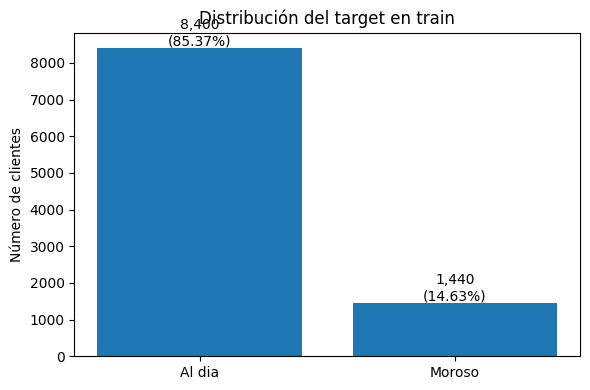

In [7]:
eda_train = X_train.copy()
eda_train[TARGET] = y_train

target_counts = eda_train[TARGET].value_counts().sort_index()
target_pct = eda_train[TARGET].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(6, 4))
labels = ['Al dia', 'Moroso']
bars = ax.bar(labels, target_counts.values)
ax.set_title('Distribución del target en train')
ax.set_ylabel('Número de clientes')
for bar, count, pct in zip(bars, target_counts.values, target_pct.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{count:,}\n({pct:.2f}%)',
        ha='center',
        va='bottom'
    )
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'target_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

## 3.2 Valores faltantes y `score_externo`

En M1, `score_externo` fue la principal variable con faltantes y el patrón era mucho más frecuente entre morosos. Se vuelve a cuantificar sobre la población binaria para verificar que la ausencia no sea ignorada durante el modelado.

,nulos,porcentaje
score_externo,854,8.68
edad,166,1.69
ingreso_mensual,0,0.00
anio_vinculacion,0,0.00
nivel_educativo,0,0.00
ciudad,0,0.00


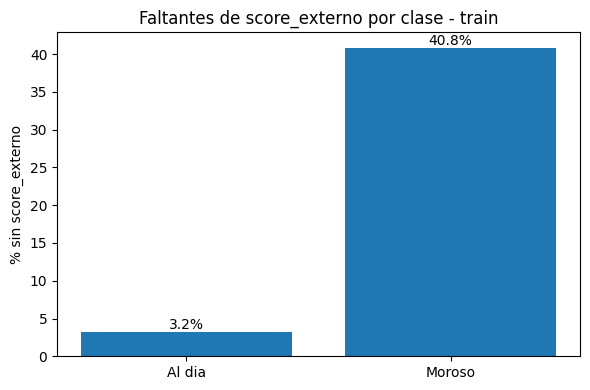

Interpretación: la ausencia de score_externo no es homogénea entre clases. Por eso no se rellena globalmente; la imputación se aprende dentro de cada fold.


In [8]:
missing_summary = pd.DataFrame({
    'nulos': eda_train[FEATURES].isna().sum(),
    'porcentaje': (eda_train[FEATURES].isna().mean() * 100).round(2),
}).sort_values('porcentaje', ascending=False)
display(missing_summary)

score_missing_by_target = (
    eda_train
    .assign(score_faltante=eda_train['score_externo'].isna())
    .groupby(TARGET)['score_faltante']
    .mean()
    .mul(100)
    .rename(index={0: 'Al dia', 1: 'Moroso'})
)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(score_missing_by_target.index, score_missing_by_target.values)
ax.set_title('Faltantes de score_externo por clase - train')
ax.set_ylabel('% sin score_externo')
for bar, value in zip(bars, score_missing_by_target.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.1f}%',
        ha='center',
        va='bottom'
    )
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'score_missing_by_target.png', dpi=300, bbox_inches='tight')
plt.show()

print(
    'Interpretación: la ausencia de score_externo no es homogénea entre clases. '
    'Por eso no se rellena globalmente; la imputación se aprende dentro de cada fold.'
)

## 3.3 Variables numéricas frente a la mora

Se comparan únicamente los cuatro predictores numéricos seguros. Los boxplots permiten observar desplazamientos entre clases sin convertir esos patrones en reglas determinísticas.

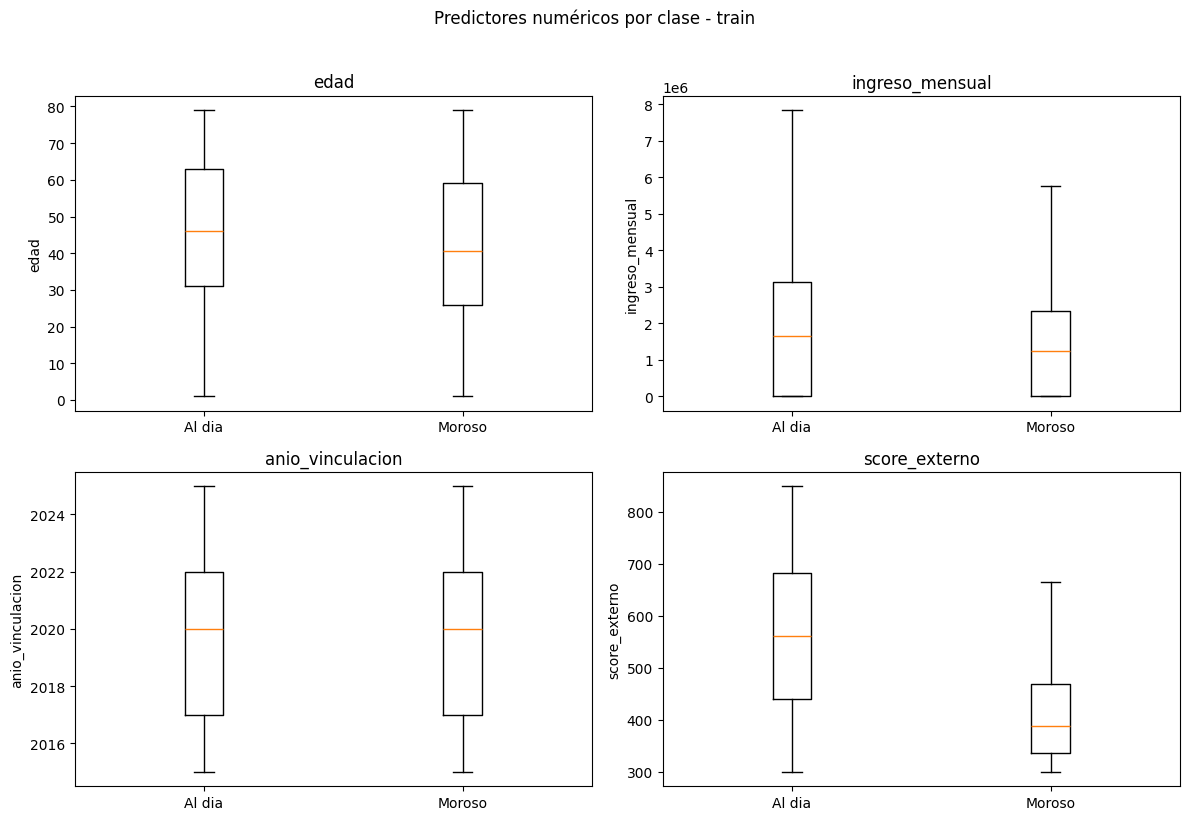

,edad,ingreso_mensual,anio_vinculacion,score_externo
target_moroso,,,,
Al dia,46.0,1659013.5,2020.0,561.0
Moroso,40.5,1229304.5,2020.0,389.0


In [9]:
eda_numeric = eda_train[NUMERIC_FEATURES + [TARGET]].copy()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.ravel(), NUMERIC_FEATURES):
    data_0 = eda_numeric.loc[eda_numeric[TARGET] == 0, feature].dropna()
    data_1 = eda_numeric.loc[eda_numeric[TARGET] == 1, feature].dropna()
    ax.boxplot([data_0, data_1], tick_labels=['Al dia', 'Moroso'], showfliers=False)
    ax.set_title(feature)
    ax.set_ylabel(feature)
plt.suptitle('Predictores numéricos por clase - train', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'numeric_features_by_target.png', dpi=300, bbox_inches='tight')
plt.show()

numeric_medians = (
    eda_numeric
    .groupby(TARGET)[NUMERIC_FEATURES]
    .median()
    .rename(index={0: 'Al dia', 1: 'Moroso'})
)
display(numeric_medians)

## 3.4 Variables categóricas

Para las variables categóricas se analiza la **tasa de mora por categoría**, no solo el volumen. Esto permite detectar grupos con diferente concentración de la clase positiva sin asumir causalidad.

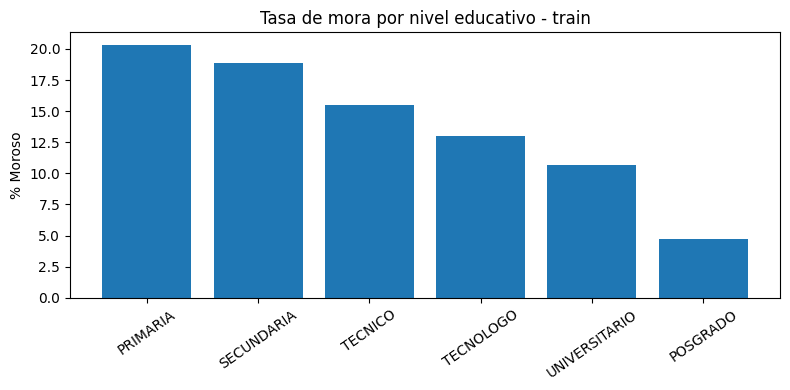

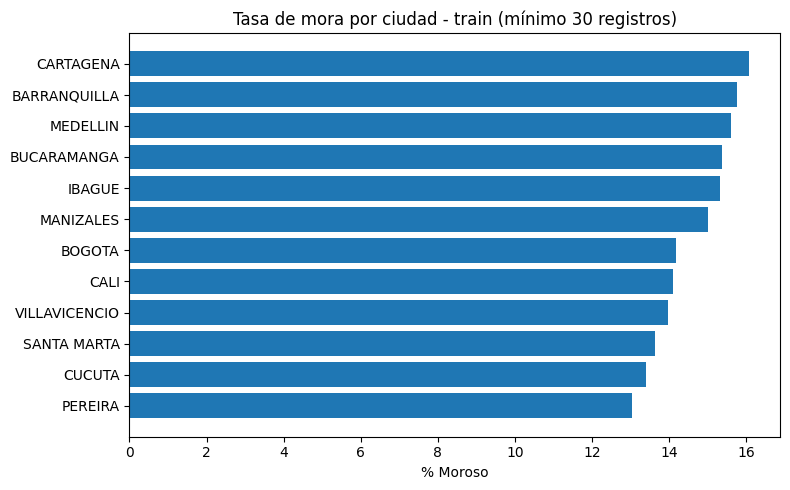

Nota: estas diferencias son descriptivas y no implican causalidad.


In [10]:
def mora_rate_table(data, feature, min_count=1):
    table = (
        data.groupby(feature)[TARGET]
        .agg(cantidad='size', tasa_mora='mean')
        .reset_index()
    )
    table = table[table['cantidad'] >= min_count].copy()
    table['tasa_mora_pct'] = table['tasa_mora'] * 100
    return table.sort_values('tasa_mora_pct', ascending=False)


education_rate = mora_rate_table(eda_train, 'nivel_educativo')
city_rate = mora_rate_table(eda_train, 'ciudad', min_count=30)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(education_rate['nivel_educativo'], education_rate['tasa_mora_pct'])
ax.set_title('Tasa de mora por nivel educativo - train')
ax.set_ylabel('% Moroso')
ax.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'mora_by_education.png', dpi=300, bbox_inches='tight')
plt.show()

city_plot = city_rate.sort_values('tasa_mora_pct')
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(city_plot['ciudad'], city_plot['tasa_mora_pct'])
ax.set_title('Tasa de mora por ciudad - train (mínimo 30 registros)')
ax.set_xlabel('% Moroso')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'mora_by_city.png', dpi=300, bbox_inches='tight')
plt.show()

print('Nota: estas diferencias son descriptivas y no implican causalidad.')

## 3.5 Correlación entre predictores numéricos seguros

Se calcula Pearson únicamente sobre las variables numéricas que realmente entran al modelo. Esto evita mezclar el análisis con variables excluidas por riesgo temporal.

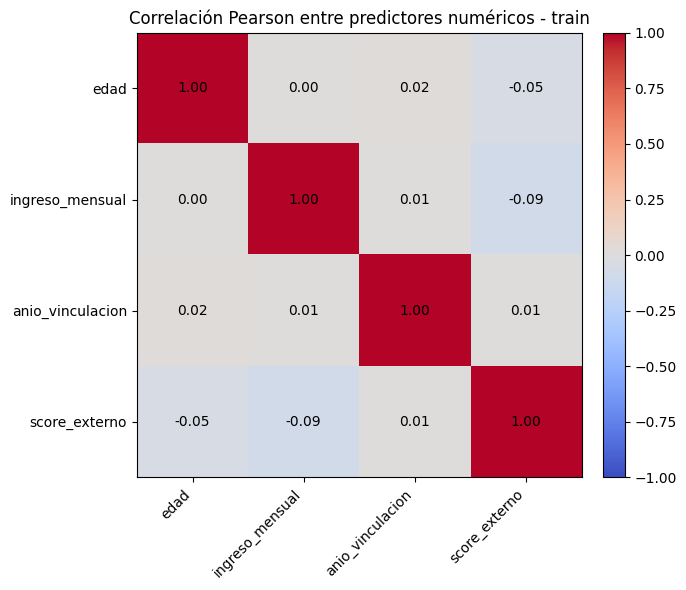

Mayor correlación absoluta entre predictores numéricos seguros: 0.093


In [11]:
corr = X_train[NUMERIC_FEATURES].corr(method='pearson')

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(corr.values, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(NUMERIC_FEATURES)), NUMERIC_FEATURES, rotation=45, ha='right')
ax.set_yticks(range(len(NUMERIC_FEATURES)), NUMERIC_FEATURES)
for i in range(len(NUMERIC_FEATURES)):
    for j in range(len(NUMERIC_FEATURES)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center')
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
ax.set_title('Correlación Pearson entre predictores numéricos - train')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

upper_triangle = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).abs()
max_corr = upper_triangle.max().max()
print(f'Mayor correlación absoluta entre predictores numéricos seguros: {max_corr:.3f}')

### Hallazgos principales del EDA

La siguiente celda resume con cifras calculadas en **train** los patrones más relevantes para el modelado. Se reportan asociaciones descriptivas; no se interpretan como relaciones causales ni como reglas de decisión aisladas.

In [12]:
score_medians = numeric_medians['score_externo']
income_medians = numeric_medians['ingreso_mensual']
age_medians = numeric_medians['edad']

print(f'1. Moroso representa {100 * y_train.mean():.2f}% del conjunto de train.')
print(
    f'2. Faltantes de score_externo: Al día {score_missing_by_target["Al dia"]:.1f}% '
    f'vs Moroso {score_missing_by_target["Moroso"]:.1f}%.'
)
print(
    f'3. Mediana score_externo: Al día {score_medians["Al dia"]:.0f} '
    f'vs Moroso {score_medians["Moroso"]:.0f}.'
)
print(
    f'4. Mediana ingreso_mensual: Al día ${income_medians["Al dia"]:,.0f} '
    f'vs Moroso ${income_medians["Moroso"]:,.0f}.'
)
print(
    f'5. Mediana edad: Al día {age_medians["Al dia"]:.0f} '
    f'vs Moroso {age_medians["Moroso"]:.0f}.'
)
print(f'6. Mayor correlación absoluta entre predictores numéricos seguros: {max_corr:.3f}.')
print(
    '7. El EDA no modifica la lista de features: las variables con temporalidad '
    'no demostrable continúan excluidas por riesgo de leakage.'
)


1. Moroso representa 14.63% del conjunto de train.
2. Faltantes de score_externo: Al día 3.2% vs Moroso 40.8%.
3. Mediana score_externo: Al día 561 vs Moroso 389.
4. Mediana ingreso_mensual: Al día $1,659,014 vs Moroso $1,229,304.
5. Mediana edad: Al día 46 vs Moroso 40.
6. Mayor correlación absoluta entre predictores numéricos seguros: 0.093.
7. El EDA no modifica la lista de features: las variables con temporalidad no demostrable continúan excluidas por riesgo de leakage.


# 4. Modelado

Se comparan dos modelos sobre **train** mediante validación cruzada estratificada de 5 folds:

- **Regresión Logística:** baseline interpretable y lineal.
- **HistGradientBoostingClassifier:** challenger capaz de capturar relaciones no lineales e interacciones.

El preprocesamiento queda encapsulado en `ColumnTransformer + Pipeline`, evitando que imputación, escalamiento o codificación aprendan información del test.

In [13]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, NUMERIC_FEATURES),
    ('cat', categorical_transformer, CATEGORICAL_FEATURES),
])

baseline_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=RANDOM_SEED,
        solver='liblinear',
    )),
])

challenger_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(
        class_weight='balanced',
        random_state=RANDOM_SEED,
        early_stopping=False,
    )),
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_SEED,
)

baseline_scores = cross_val_score(
    baseline_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
)
challenger_scores = cross_val_score(
    challenger_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
)

comparison = pd.DataFrame({
    'modelo': ['Regresion Logistica', 'HistGradientBoosting'],
    'auc_cv_media': [baseline_scores.mean(), challenger_scores.mean()],
    'auc_cv_std': [baseline_scores.std(), challenger_scores.std()],
}).round(4)

display(comparison)

,modelo,auc_cv_media,auc_cv_std
0,Regresion Logistica,0.7353,0.0049
1,HistGradientBoosting,0.8593,0.0070


## 4.1 Optimización del challenger con Optuna

Se usa Optuna con `TPESampler`, semilla 42 y 50 trials. Cada trial se evalúa con AUC-ROC promedio en 5-fold CV usando únicamente `X_train` e `y_train`. El conjunto de test permanece aislado.

In [14]:
SEARCH_SPACE = {
    'learning_rate': '0.02 a 0.20 (log)',
    'max_iter': '100 a 350',
    'max_leaf_nodes': '15 a 63',
    'min_samples_leaf': '10 a 60',
    'l2_regularization': '1e-5 a 10 (log)',
}

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED),
)


def objective(trial):
    params = {
        'classifier__learning_rate': trial.suggest_float(
            'learning_rate', 0.02, 0.20, log=True
        ),
        'classifier__max_iter': trial.suggest_int(
            'max_iter', 100, 350, step=50
        ),
        'classifier__max_leaf_nodes': trial.suggest_int(
            'max_leaf_nodes', 15, 63
        ),
        'classifier__min_samples_leaf': trial.suggest_int(
            'min_samples_leaf', 10, 60
        ),
        'classifier__l2_regularization': trial.suggest_float(
            'l2_regularization', 1e-5, 10.0, log=True
        ),
    }
    candidate = clone(challenger_pipeline).set_params(**params)
    scores = cross_val_score(
        candidate,
        X_train,
        y_train,
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1,
    )
    return float(scores.mean())


study.optimize(
    objective,
    n_trials=50,
    n_jobs=1,
    show_progress_bar=False,
)

best_pipeline = clone(challenger_pipeline).set_params(
    **{f'classifier__{key}': value for key, value in study.best_params.items()}
)
best_pipeline.fit(X_train, y_train)

print(f'Mejor AUC CV: {study.best_value:.4f}')
print('Mejores hiperparámetros:')
for key, value in study.best_params.items():
    print(f'  - {key}: {value}')

Mejor AUC CV: 0.8692
Mejores hiperparámetros:
  - learning_rate: 0.021129187785442333
  - max_iter: 150
  - max_leaf_nodes: 15
  - min_samples_leaf: 26
  - l2_regularization: 5.4753321290292246e-05


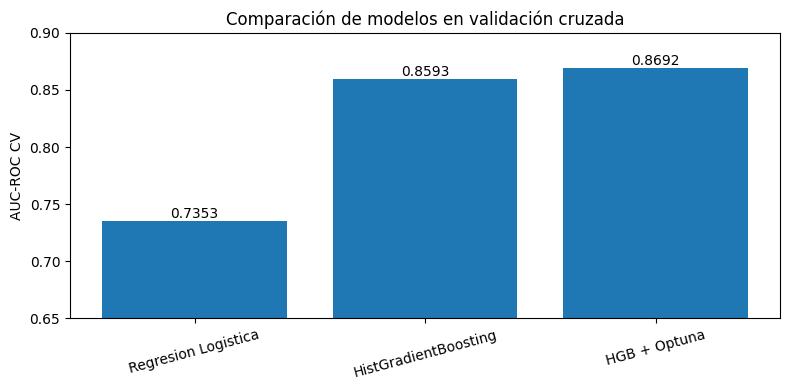

Mejora del challenger frente al baseline: 0.1240 AUC.
Mejora adicional de Optuna: 0.0100 AUC.


In [15]:
model_comparison = pd.DataFrame({
    'modelo': [
        'Regresion Logistica',
        'HistGradientBoosting',
        'HGB + Optuna',
    ],
    'auc_cv': [
        baseline_scores.mean(),
        challenger_scores.mean(),
        study.best_value,
    ],
})

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(model_comparison['modelo'], model_comparison['auc_cv'])
ax.set_ylim(0.65, 0.90)
ax.set_ylabel('AUC-ROC CV')
ax.set_title('Comparación de modelos en validación cruzada')
ax.tick_params(axis='x', rotation=15)
for bar, value in zip(bars, model_comparison['auc_cv']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.4f}',
        ha='center',
        va='bottom'
    )
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(
    f'Mejora del challenger frente al baseline: '
    f'{challenger_scores.mean() - baseline_scores.mean():.4f} AUC.'
)
print(
    f'Mejora adicional de Optuna: '
    f'{study.best_value - challenger_scores.mean():.4f} AUC.'
)

## 4.2 Selección del threshold operativo

El threshold **no se ajusta sobre test**. Se generan predicciones *out-of-fold* en train y se buscan thresholds entre 0,05 y 0,95. Se exige `precision >= 0.40` y `recall >= 0.70`; entre las alternativas válidas se selecciona la de mayor F1.

In [16]:
y_proba_oof = cross_val_predict(
    clone(best_pipeline),
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1,
)[:, 1]

rows = []
for threshold in np.arange(0.05, 0.951, 0.01):
    y_pred_oof = (y_proba_oof >= threshold).astype(int)
    rows.append({
        'threshold': float(threshold),
        'precision': precision_score(y_train, y_pred_oof, zero_division=0),
        'recall': recall_score(y_train, y_pred_oof, zero_division=0),
        'f1': f1_score(y_train, y_pred_oof, zero_division=0),
    })

threshold_results = pd.DataFrame(rows)
valid_thresholds = threshold_results[
    (threshold_results['precision'] >= 0.40) &
    (threshold_results['recall'] >= 0.70)
].copy()

if not valid_thresholds.empty:
    best_threshold_row = valid_thresholds.sort_values(
        ['f1', 'recall'], ascending=False
    ).iloc[0]
    threshold_status = 'Cumple precision >= 0.40 y recall >= 0.70 en OOF.'
else:
    best_threshold_row = threshold_results.sort_values(
        ['f1', 'recall'], ascending=False
    ).iloc[0]
    threshold_status = 'No hubo threshold que cumpliera ambas metas; se seleccionó por F1.'

optimal_threshold = float(best_threshold_row['threshold'])

print(threshold_status)
print(f'Threshold: {optimal_threshold:.2f}')
print(f'Precision OOF: {best_threshold_row["precision"]:.4f}')
print(f'Recall OOF   : {best_threshold_row["recall"]:.4f}')
print(f'F1 OOF       : {best_threshold_row["f1"]:.4f}')

Cumple precision >= 0.40 y recall >= 0.70 en OOF.
Threshold: 0.59
Precision OOF: 0.4487
Recall OOF   : 0.7111
F1 OOF       : 0.5502


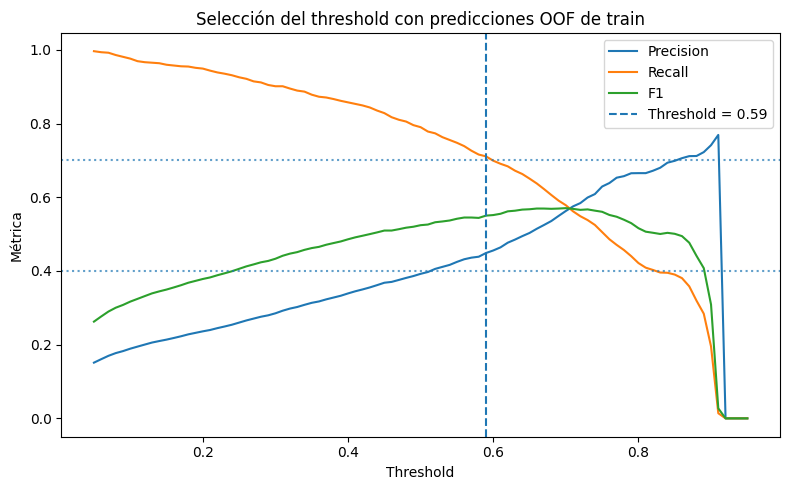

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(threshold_results['threshold'], threshold_results['precision'], label='Precision')
ax.plot(threshold_results['threshold'], threshold_results['recall'], label='Recall')
ax.plot(threshold_results['threshold'], threshold_results['f1'], label='F1')
ax.axvline(optimal_threshold, linestyle='--', label=f'Threshold = {optimal_threshold:.2f}')
ax.axhline(0.40, linestyle=':', alpha=0.7)
ax.axhline(0.70, linestyle=':', alpha=0.7)
ax.set_xlabel('Threshold')
ax.set_ylabel('Métrica')
ax.set_title('Selección del threshold con predicciones OOF de train')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'threshold_metrics.png', dpi=300, bbox_inches='tight')
plt.show()

# 5. Evaluación final del modelo

El modelo y el threshold quedan congelados antes de tocar test. La evaluación final reporta las métricas definidas en M2 y complementa el resultado con curvas y análisis explícito de falsos positivos y falsos negativos.

In [18]:
best_pipeline.fit(X_train, y_train)
y_proba_test = best_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_proba_test >= optimal_threshold).astype(int)

auc_test = roc_auc_score(y_test, y_proba_test)
precision_test = precision_score(y_test, y_pred_test, zero_division=0)
recall_test = recall_score(y_test, y_pred_test, zero_division=0)
f1_test = f1_score(y_test, y_pred_test, zero_division=0)

metrics_table = pd.DataFrame({
    'metrica': ['AUC-ROC', 'Precision Moroso', 'Recall Moroso', 'F1 Moroso'],
    'resultado': [auc_test, precision_test, recall_test, f1_test],
})
display(metrics_table.style.format({'resultado': '{:.4f}'}))

print('\nClassification report:')
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Al dia', 'Moroso'],
    digits=4,
    zero_division=0,
))

,metrica,resultado
0,AUC-ROC,0.8681
1,Precision Moroso,0.4470
2,Recall Moroso,0.7028
3,F1 Moroso,0.5464



Classification report:
              precision    recall  f1-score   support

      Al dia     0.9435    0.8510    0.8948      2100
      Moroso     0.4470    0.7028    0.5464       360

    accuracy                         0.8293      2460
   macro avg     0.6953    0.7769    0.7206      2460
weighted avg     0.8708    0.8293    0.8439      2460



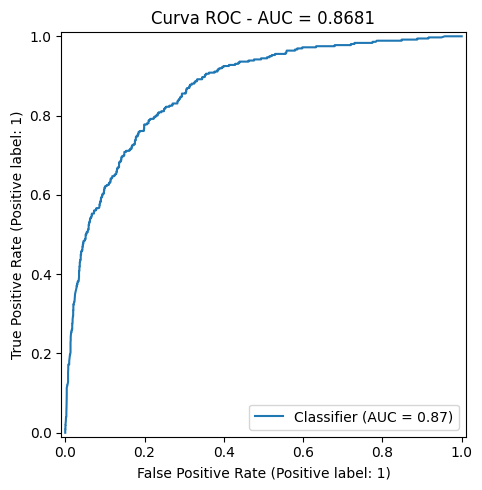

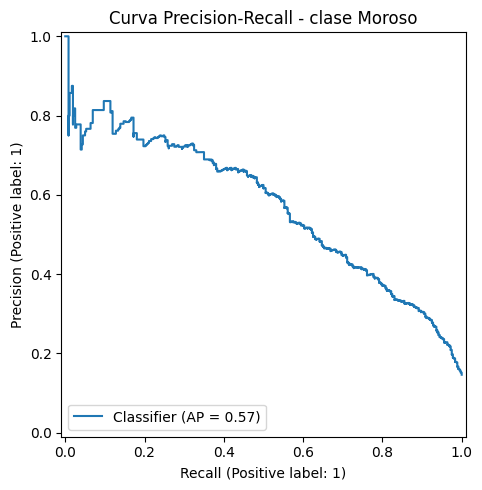

In [19]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, y_proba_test, ax=ax)
ax.set_title(f'Curva ROC - AUC = {auc_test:.4f}')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_test, y_proba_test, ax=ax)
ax.set_title('Curva Precision-Recall - clase Moroso')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'precision_recall_curve.png', dpi=300, bbox_inches='tight')
plt.show()

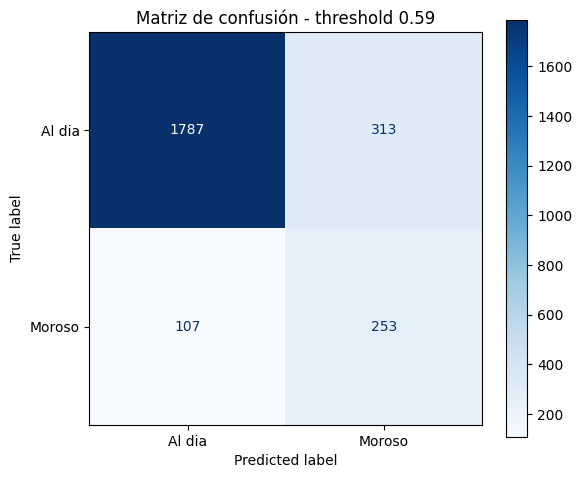

Verdaderos negativos: 1787
Falsos positivos:      313
Falsos negativos:      107
Verdaderos positivos:  253


In [20]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test,
    display_labels=['Al dia', 'Moroso'],
    cmap='Blues',
    ax=ax,
)
ax.set_title(f'Matriz de confusión - threshold {optimal_threshold:.2f}')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()
print(f'Verdaderos negativos: {tn}')
print(f'Falsos positivos:      {fp}')
print(f'Falsos negativos:      {fn}')
print(f'Verdaderos positivos:  {tp}')

## 5.1 Interpretación de errores

- **Falso negativo (Moroso clasificado como Al día):** es el error más sensible para FrescaMar porque puede dejar sin alerta a un cliente que posteriormente presenta mora.
- **Falso positivo (Al día clasificado como Moroso):** genera revisión o restricción innecesaria sobre un cliente cumplido.

El threshold busca un compromiso entre ambos errores. Por eso se definió previamente con validación OOF y no se retoca después de observar test.

In [21]:
print(
    f'El modelo detecta {tp} de {tp + fn} morosos del test '
    f'({recall_test:.2%} de recall).'
)
print(
    f'De {tp + fp} alertas emitidas, {tp} corresponden a morosos reales '
    f'({precision_test:.2%} de precision).'
)
print(
    f'Quedan {fn} morosos sin detectar y se generan {fp} falsas alertas.'
)

El modelo detecta 253 de 360 morosos del test (70.28% de recall).
De 566 alertas emitidas, 253 corresponden a morosos reales (44.70% de precision).
Quedan 107 morosos sin detectar y se generan 313 falsas alertas.


## 5.2 Verificación de generalización

Se compara AUC de train y test. Si la diferencia supera 0,10, el notebook **se detiene** para revisar leakage o sobreajuste. No se modifica el modelo después de mirar test.

In [22]:
train_proba = best_pipeline.predict_proba(X_train)[:, 1]
auc_train = roc_auc_score(y_train, train_proba)
auc_gap = abs(auc_train - auc_test)

print(f'AUC Train: {auc_train:.4f}')
print(f'AUC Test : {auc_test:.4f}')
print(f'Gap      : {auc_gap:.4f}')

if auc_gap > 0.10:
    raise RuntimeError(
        'ALERTA: abs(AUC_train - AUC_test) > 0.10. '
        'Revisar leakage/sobreajuste sin reajustar sobre test.'
    )

leakage_status = 'Diferencia aceptable - pipeline validado'
print(leakage_status)

AUC Train: 0.8935
AUC Test : 0.8681
Gap      : 0.0254
Diferencia aceptable - pipeline validado


# 6. Serialización y artefactos del prototipo

El pipeline completo se serializa con `joblib`, se vuelve a cargar y se verifica que reproduzca las probabilidades de una muestra. También se exportan las métricas principales para trazabilidad.

In [23]:
pipeline_path = MODEL_DIR / 'solaris_hgb_v1_20260915.pkl'
joblib.dump(best_pipeline, pipeline_path)
loaded_pipeline = joblib.load(pipeline_path)

original_sample = best_pipeline.predict_proba(X_test.head(10))[:, 1]
loaded_sample = loaded_pipeline.predict_proba(X_test.head(10))[:, 1]
pkl_load_ok = bool(np.allclose(original_sample, loaded_sample))
if not pkl_load_ok:
    raise RuntimeError('El PKL no reproduce las predicciones del pipeline original.')

metrics = {
    'fecha_ejecucion': datetime.now().isoformat(timespec='seconds'),
    'random_seed': RANDOM_SEED,
    'entorno': {
        'python': sys.version.split()[0],
        'numpy': np.__version__,
        'pandas': pd.__version__,
        'scikit_learn': sklearn.__version__,
        'matplotlib': matplotlib.__version__,
        'joblib': joblib.__version__,
        'optuna': optuna.__version__,
    },
    'n_filas_modelado': int(len(df_model)),
    'n_ciudades_normalizadas': int(df_model['ciudad'].nunique(dropna=True)),
    'features': FEATURES,
    'modelo_final': 'HistGradientBoostingClassifier',
    'metodo_optimizacion': 'Optuna - TPESampler',
    'n_trials': int(len(study.trials)),
    'best_cv_auc': float(study.best_value),
    'mejores_hiperparametros': study.best_params,
    'threshold_operativo': float(optimal_threshold),
    'auc_train': float(auc_train),
    'auc_test': float(auc_test),
    'diferencia_auc_train_test': float(auc_gap),
    'precision_test': float(precision_test),
    'recall_test': float(recall_test),
    'f1_test': float(f1_test),
    'estado_leakage': leakage_status,
    'pkl_cargable': pkl_load_ok,
}

metrics_path = OUTPUT_DIR / 'metricas_m3.json'
with open(metrics_path, 'w', encoding='utf-8') as file:
    json.dump(metrics, file, ensure_ascii=False, indent=2)

print('Pipeline:', pipeline_path)
print('Métricas:', metrics_path)
print('PKL cargable:', pkl_load_ok)
print('Figuras generadas:')
for figure_path in sorted(FIGURES_DIR.glob('*.png')):
    print('-', figure_path)


Pipeline: models/artifacts/solaris_hgb_v1_20260915.pkl
Métricas: outputs/metricas_m3.json
PKL cargable: True
Figuras generadas:
- reports/figures/confusion_matrix.png
- reports/figures/correlation_matrix.png
- reports/figures/model_comparison.png
- reports/figures/mora_by_city.png
- reports/figures/mora_by_education.png
- reports/figures/numeric_features_by_target.png
- reports/figures/precision_recall_curve.png
- reports/figures/roc_curve.png
- reports/figures/score_missing_by_target.png
- reports/figures/target_distribution.png
- reports/figures/threshold_metrics.png


# 7. Conclusiones

La conclusión se genera a partir de los resultados de **esta ejecución** para evitar inconsistencias con métricas de módulos anteriores.

In [24]:
print('Modelo final: HistGradientBoostingClassifier optimizado con Optuna')
print(f'AUC CV optimizado : {study.best_value:.4f}')
print(f'AUC Test          : {auc_test:.4f}')
print(f'Precision Moroso  : {precision_test:.4f}')
print(f'Recall Moroso     : {recall_test:.4f}')
print(f'F1 Moroso         : {f1_test:.4f}')
print(f'Threshold         : {optimal_threshold:.2f}')
print(f'Gap Train-Test    : {auc_gap:.4f}')
print()
print(
    f'El modelo supera la línea base logística en '
    f'{study.best_value - baseline_scores.mean():.4f} puntos de AUC CV.'
)
print(
    f'En test detecta {tp} de {tp + fn} morosos y produce {fp} falsas alertas. '
    'El threshold se seleccionó exclusivamente con predicciones OOF de train.'
)


Modelo final: HistGradientBoostingClassifier optimizado con Optuna
AUC CV optimizado : 0.8692
AUC Test          : 0.8681
Precision Moroso  : 0.4470
Recall Moroso     : 0.7028
F1 Moroso         : 0.5464
Threshold         : 0.59
Gap Train-Test    : 0.0254

El modelo supera la línea base logística en 0.1340 puntos de AUC CV.
En test detecta 253 de 360 morosos y produce 313 falsas alertas. El threshold se seleccionó exclusivamente con predicciones OOF de train.


### Limitaciones y siguientes pasos

1. El archivo actual es un *snapshot*; falta `fecha_corte`/`fecha_evento` para una validación temporal real.
2. `score_externo` presenta un patrón de faltantes asociado a la clase y debe seguir monitoreándose.
3. La normalización de `ciudad` se valida explícitamente; cualquier categoría no resuelta debe revisarse antes de considerar cerrada la limpieza.
4. El modelo es un prototipo de **soporte a la decisión**, no un sistema de aprobación/negación automática.
5. Antes de producción se requiere validación *out-of-time*, análisis de calibración, monitoreo de *drift* y validación de impacto con FrescaMar.

# 8. Módulo 4 — Evaluación crítica: validación, interpretabilidad, sesgos e impacto ético

Esta sección consolida la evidencia exigida para la entrega del Módulo 4 sin alterar el flujo técnico del Módulo 3. Incluye validación robusta, interpretabilidad SHAP global y local, análisis de sesgos y equidad, riesgos específicos de SOLARIS y una recomendación explícita de despliegue.


In [25]:
# Imports adicionales exclusivos del Módulo 4
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score
from sklearn.model_selection import cross_validate

M4_OUTPUT_DIR = OUTPUT_DIR / 'modulo4'
M4_FIGURES_DIR = FIGURES_DIR / 'modulo4'
M4_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
M4_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print('Directorio de resultados M4:', M4_OUTPUT_DIR)
print('Directorio de figuras M4   :', M4_FIGURES_DIR)

Directorio de resultados M4: outputs/modulo4
Directorio de figuras M4   : reports/figures/modulo4


## 8.1 Validación cruzada multimetric y comparación con la línea base

El Módulo 3 ya comparó los modelos mediante AUC-ROC. Para la Unidad 4 se amplía la validación a varias métricas y se reporta la variabilidad entre folds. La comparación se realiza exclusivamente sobre `train` con la misma validación cruzada estratificada de 5 folds.

modelo,HGB + Optuna,Regresion Logistica
metrica,,
auc_roc,0.8692,0.7353
average_precision,0.5776,0.3054
f1,0.5245,0.3643
precision,0.3926,0.2485
recall,0.7903,0.6819


,modelo,fold,auc_roc,average_precision,precision,recall,f1
0,HGB + Optuna,1,0.8737,0.6160,0.3924,0.7847,0.5231
1,HGB + Optuna,2,0.8824,0.5814,0.4194,0.8125,0.5532
2,HGB + Optuna,3,0.8659,0.5507,0.3924,0.7847,0.5231
3,HGB + Optuna,4,0.8737,0.6186,0.3839,0.8090,0.5207
4,HGB + Optuna,5,0.8505,0.5215,0.3750,0.7604,0.5023


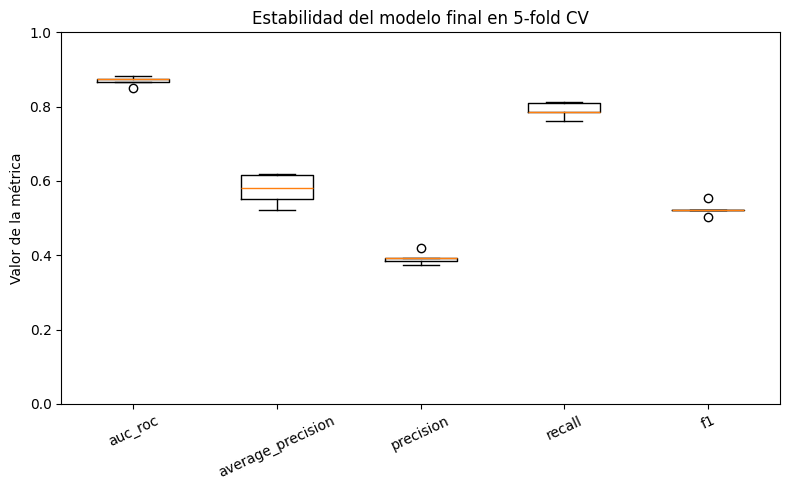

In [26]:
cv_scoring = {
    'auc_roc': 'roc_auc',
    'average_precision': 'average_precision',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
}

models_for_cv = {
    'Regresion Logistica': baseline_pipeline,
    'HGB + Optuna': best_pipeline,
}

cv_rows = []
cv_fold_tables = {}

for model_name, model in models_for_cv.items():
    result = cross_validate(
        clone(model),
        X_train,
        y_train,
        cv=cv,
        scoring=cv_scoring,
        n_jobs=-1,
        return_train_score=False,
    )

    fold_table = pd.DataFrame({
        'fold': np.arange(1, cv.get_n_splits() + 1),
        **{
            metric: result[f'test_{metric}']
            for metric in cv_scoring
        }
    })
    fold_table.insert(0, 'modelo', model_name)
    cv_fold_tables[model_name] = fold_table

    for metric in cv_scoring:
        values = result[f'test_{metric}']
        cv_rows.append({
            'modelo': model_name,
            'metrica': metric,
            'media': float(np.mean(values)),
            'desviacion_std': float(np.std(values, ddof=1)),
            'minimo': float(np.min(values)),
            'maximo': float(np.max(values)),
        })

cv_multimetric_summary = pd.DataFrame(cv_rows)
cv_multimetric_folds = pd.concat(cv_fold_tables.values(), ignore_index=True)

display(
    cv_multimetric_summary.pivot(
        index='metrica', columns='modelo', values='media'
    ).round(4)
)

display(cv_fold_tables['HGB + Optuna'].round(4))

cv_multimetric_summary.to_csv(
    M4_OUTPUT_DIR / 'validacion_cruzada_multimetric_resumen.csv',
    index=False,
    encoding='utf-8-sig',
)
cv_multimetric_folds.to_csv(
    M4_OUTPUT_DIR / 'validacion_cruzada_multimetric_folds.csv',
    index=False,
    encoding='utf-8-sig',
)

fig, ax = plt.subplots(figsize=(8, 5))
hgb_folds = cv_fold_tables['HGB + Optuna']
ax.boxplot(
    [hgb_folds[m].values for m in cv_scoring],
    tick_labels=list(cv_scoring.keys()),
)
ax.set_ylim(0, 1)
ax.set_ylabel('Valor de la métrica')
ax.set_title('Estabilidad del modelo final en 5-fold CV')
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.savefig(M4_FIGURES_DIR / 'cv_multimetric_estabilidad.png', dpi=300, bbox_inches='tight')
plt.show()

## 8.2 Sensibilidad al threshold operativo

El threshold final permanece congelado. Este análisis muestra cómo cambian precision, recall, F1 y los errores al variar el punto de corte. Para evitar reajustar sobre `test`, se utilizan las probabilidades **out-of-fold de train** calculadas en el Módulo 3.

,threshold,precision,recall,f1,tasa_alerta,falsos_positivos,falsos_negativos,verdaderos_positivos,verdaderos_negativos
0,0.40,0.3391,0.8576,0.4860,0.3701,2407,205,1235,5993
1,0.50,0.3923,0.7903,0.5243,0.2948,1763,302,1138,6637
2,0.59,0.4487,0.7111,0.5502,0.2319,1258,416,1024,7142
3,0.65,0.5032,0.6507,0.5675,0.1892,925,503,937,7475
4,0.70,0.5628,0.5785,0.5705,0.1504,647,607,833,7753


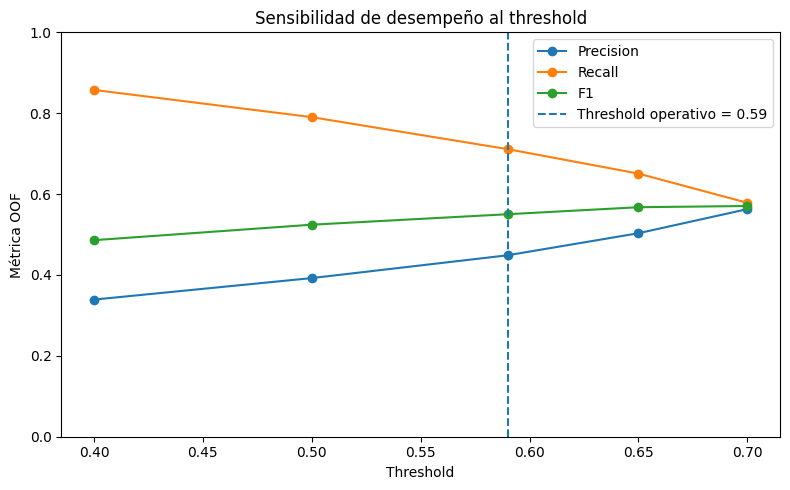

In [27]:
thresholds_sensitivity = np.array(sorted(set([
    0.40,
    0.50,
    round(float(optimal_threshold), 2),
    0.65,
    0.70,
])))

threshold_sensitivity_rows = []
for threshold in thresholds_sensitivity:
    y_pred_thr = (y_proba_oof >= threshold).astype(int)
    tn_thr, fp_thr, fn_thr, tp_thr = confusion_matrix(y_train, y_pred_thr).ravel()

    threshold_sensitivity_rows.append({
        'threshold': float(threshold),
        'precision': precision_score(y_train, y_pred_thr, zero_division=0),
        'recall': recall_score(y_train, y_pred_thr, zero_division=0),
        'f1': f1_score(y_train, y_pred_thr, zero_division=0),
        'tasa_alerta': float(np.mean(y_pred_thr)),
        'falsos_positivos': int(fp_thr),
        'falsos_negativos': int(fn_thr),
        'verdaderos_positivos': int(tp_thr),
        'verdaderos_negativos': int(tn_thr),
    })

threshold_sensitivity = pd.DataFrame(threshold_sensitivity_rows)
display(threshold_sensitivity.round(4))

threshold_sensitivity.to_csv(
    M4_OUTPUT_DIR / 'sensibilidad_threshold_oof.csv',
    index=False,
    encoding='utf-8-sig',
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(threshold_sensitivity['threshold'], threshold_sensitivity['precision'], marker='o', label='Precision')
ax.plot(threshold_sensitivity['threshold'], threshold_sensitivity['recall'], marker='o', label='Recall')
ax.plot(threshold_sensitivity['threshold'], threshold_sensitivity['f1'], marker='o', label='F1')
ax.axvline(optimal_threshold, linestyle='--', label=f'Threshold operativo = {optimal_threshold:.2f}')
ax.set_ylim(0, 1)
ax.set_xlabel('Threshold')
ax.set_ylabel('Métrica OOF')
ax.set_title('Sensibilidad de desempeño al threshold')
ax.legend()
plt.tight_layout()
plt.savefig(M4_FIGURES_DIR / 'sensibilidad_threshold.png', dpi=300, bbox_inches='tight')
plt.show()

## 8.3 Prueba de robustez ante mayor ausencia de `score_externo`

`score_externo` presenta faltantes y su ausencia está asociada con la clase en el EDA. Para evaluar la robustez del pipeline se realiza un *stress test*: sobre copias del `test` se oculta aleatoriamente una fracción adicional de los valores disponibles de `score_externo`, sin reentrenar el modelo. El pipeline debe resolver esos faltantes con la imputación aprendida exclusivamente en `train`.

Esta prueba **no modifica el test original ni el modelo**; solo mide sensibilidad de las predicciones ante deterioro de disponibilidad de una variable relevante.

,faltante_adicional_score,auc_media,auc_std,ap_media,precision_media,recall_media,f1_media,f1_std
0,0.0,0.8681,0.0000,0.5708,0.4470,0.7028,0.5464,0.0000
1,0.1,0.8223,0.0035,0.3961,0.3497,0.7347,0.4739,0.0037
2,0.2,0.7815,0.0066,0.3233,0.2910,0.7650,0.4216,0.0064
3,0.3,0.7387,0.0063,0.2763,0.2490,0.7867,0.3783,0.0046
4,0.5,0.6780,0.0092,0.2314,0.2007,0.8457,0.3245,0.0050


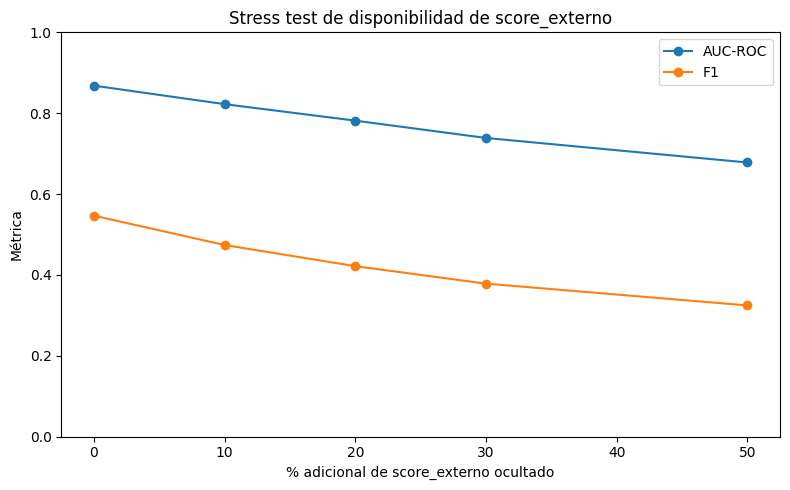

In [28]:
rng_master = np.random.default_rng(RANDOM_SEED)
extra_missing_rates = [0.00, 0.10, 0.20, 0.30, 0.50]
n_repeats = 20

robustness_rows = []
available_idx = np.flatnonzero(X_test['score_externo'].notna().to_numpy())

for rate in extra_missing_rates:
    repeats = 1 if rate == 0 else n_repeats

    for repeat in range(repeats):
        X_stress = X_test.copy()

        if rate > 0 and len(available_idx) > 0:
            n_mask = int(round(rate * len(available_idx)))
            n_mask = min(n_mask, len(available_idx))
            rng = np.random.default_rng(RANDOM_SEED + repeat + int(rate * 1000))
            mask_positions = rng.choice(available_idx, size=n_mask, replace=False)
            X_stress.iloc[mask_positions, X_stress.columns.get_loc('score_externo')] = np.nan

        proba_stress = best_pipeline.predict_proba(X_stress)[:, 1]
        pred_stress = (proba_stress >= optimal_threshold).astype(int)

        robustness_rows.append({
            'faltante_adicional_score': rate,
            'repeticion': repeat + 1,
            'auc_roc': roc_auc_score(y_test, proba_stress),
            'average_precision': average_precision_score(y_test, proba_stress),
            'precision': precision_score(y_test, pred_stress, zero_division=0),
            'recall': recall_score(y_test, pred_stress, zero_division=0),
            'f1': f1_score(y_test, pred_stress, zero_division=0),
        })

robustness_detail = pd.DataFrame(robustness_rows)
robustness_summary = (
    robustness_detail
    .groupby('faltante_adicional_score')
    .agg(
        auc_media=('auc_roc', 'mean'),
        auc_std=('auc_roc', 'std'),
        ap_media=('average_precision', 'mean'),
        precision_media=('precision', 'mean'),
        recall_media=('recall', 'mean'),
        f1_media=('f1', 'mean'),
        f1_std=('f1', 'std'),
    )
    .reset_index()
    .fillna(0)
)

display(robustness_summary.round(4))

robustness_detail.to_csv(
    M4_OUTPUT_DIR / 'robustez_score_faltante_detalle.csv',
    index=False,
    encoding='utf-8-sig',
)
robustness_summary.to_csv(
    M4_OUTPUT_DIR / 'robustez_score_faltante_resumen.csv',
    index=False,
    encoding='utf-8-sig',
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(robustness_summary['faltante_adicional_score'] * 100, robustness_summary['auc_media'], marker='o', label='AUC-ROC')
ax.plot(robustness_summary['faltante_adicional_score'] * 100, robustness_summary['f1_media'], marker='o', label='F1')
ax.set_xlabel('% adicional de score_externo ocultado')
ax.set_ylabel('Métrica')
ax.set_ylim(0, 1)
ax.set_title('Stress test de disponibilidad de score_externo')
ax.legend()
plt.tight_layout()
plt.savefig(M4_FIGURES_DIR / 'robustez_score_faltante.png', dpi=300, bbox_inches='tight')
plt.show()

## 8.4 Auditoría de desempeño por subgrupos

Se cuantifican diferencias entre segmentos usando tamaño del grupo, prevalencia real de mora, tasa de alertas, precision, recall, F1, FPR, FNR y AUC-ROC cuando ambas clases están presentes.

Los grupos evaluados son:
- `nivel_educativo`
- `ciudad`
- grupos de edad
- cuartiles de ingreso definidos con `train`
- cuartiles de año de vinculación definidos con `train`
- disponibilidad de `score_externo`

Para evitar conclusiones inestables, el resumen de brechas prioriza grupos con al menos 50 observaciones, 10 positivos y 10 negativos. Una brecha no equivale automáticamente a discriminación: debe interpretarse junto con tamaño de muestra, prevalencia y contexto de negocio.

In [29]:
audit_test = X_test.copy()
audit_test[TARGET] = y_test.to_numpy()
audit_test['proba_moroso'] = y_proba_test
audit_test['pred_moroso'] = y_pred_test

def quantile_edges_from_train(series, q=4):
    clean = pd.to_numeric(series, errors='coerce').dropna()
    quantiles = np.linspace(0, 1, q + 1)
    edges = np.unique(clean.quantile(quantiles).to_numpy(dtype=float))
    if len(edges) < 3:
        return np.array([-np.inf, np.inf])
    edges[0] = -np.inf
    edges[-1] = np.inf
    return edges

# Grupos de edad con cortes interpretables.
audit_test['grupo_edad'] = pd.cut(
    audit_test['edad'],
    bins=[-np.inf, 29, 39, 49, 59, np.inf],
    labels=['<30', '30-39', '40-49', '50-59', '60+'],
)

# Cuartiles definidos a partir de train para no usar la distribución de test para fijar cortes.
income_edges = quantile_edges_from_train(X_train['ingreso_mensual'], q=4)
tenure_edges = quantile_edges_from_train(X_train['anio_vinculacion'], q=4)

audit_test['grupo_ingreso'] = pd.cut(
    audit_test['ingreso_mensual'],
    bins=income_edges,
    include_lowest=True,
    duplicates='drop',
)
audit_test['grupo_vinculacion'] = pd.cut(
    audit_test['anio_vinculacion'],
    bins=tenure_edges,
    include_lowest=True,
    duplicates='drop',
)
audit_test['score_disponible'] = np.where(
    audit_test['score_externo'].isna(),
    'Score faltante',
    'Score disponible',
)

# Etiquetas explícitas para valores categóricos faltantes.
for col in ['nivel_educativo', 'ciudad']:
    audit_test[col] = audit_test[col].astype('object').where(
        audit_test[col].notna(), 'FALTANTE'
    )


def subgroup_metrics(data, group_col):
    rows = []

    for group_value, group in data.groupby(group_col, observed=False, dropna=False):
        y_true_g = group[TARGET].astype(int).to_numpy()
        y_pred_g = group['pred_moroso'].astype(int).to_numpy()
        y_prob_g = group['proba_moroso'].to_numpy()

        cm = confusion_matrix(y_true_g, y_pred_g, labels=[0, 1])
        tn_g, fp_g, fn_g, tp_g = cm.ravel()
        positives = int(tp_g + fn_g)
        negatives = int(tn_g + fp_g)

        auc_g = np.nan
        if len(np.unique(y_true_g)) == 2:
            auc_g = roc_auc_score(y_true_g, y_prob_g)

        rows.append({
            'variable_grupo': group_col,
            'grupo': str(group_value),
            'n': int(len(group)),
            'positivos_reales': positives,
            'negativos_reales': negatives,
            'prevalencia_mora': float(np.mean(y_true_g)),
            'tasa_alerta': float(np.mean(y_pred_g)),
            'precision': precision_score(y_true_g, y_pred_g, zero_division=0),
            'recall_tpr': recall_score(y_true_g, y_pred_g, zero_division=0),
            'f1': f1_score(y_true_g, y_pred_g, zero_division=0),
            'fpr': float(fp_g / negatives) if negatives > 0 else np.nan,
            'fnr': float(fn_g / positives) if positives > 0 else np.nan,
            'auc_roc': auc_g,
            'tn': int(tn_g),
            'fp': int(fp_g),
            'fn': int(fn_g),
            'tp': int(tp_g),
        })

    return pd.DataFrame(rows)

subgroup_columns = [
    'nivel_educativo',
    'ciudad',
    'grupo_edad',
    'grupo_ingreso',
    'grupo_vinculacion',
    'score_disponible',
]

subgroup_tables = {
    col: subgroup_metrics(audit_test, col)
    for col in subgroup_columns
}

subgroup_metrics_all = pd.concat(subgroup_tables.values(), ignore_index=True)

for col, table in subgroup_tables.items():
    print(f'\n--- {col} ---')
    display(table.sort_values('n', ascending=False).round(4))
    table.to_csv(
        M4_OUTPUT_DIR / f'sesgo_subgrupos_{col}.csv',
        index=False,
        encoding='utf-8-sig',
    )

subgroup_metrics_all.to_csv(
    M4_OUTPUT_DIR / 'sesgo_subgrupos_todos.csv',
    index=False,
    encoding='utf-8-sig',
)


--- nivel_educativo ---


,variable_grupo,grupo,n,positivos_reales,negativos_reales,prevalencia_mora,tasa_alerta,precision,recall_tpr,f1,fpr,fnr,auc_roc,tn,fp,fn,tp
2,nivel_educativo,SECUNDARIA,627,144,483,0.2297,0.3270,0.5415,0.7708,0.6361,0.1946,0.2292,0.8643,389,94,33,111
5,nivel_educativo,UNIVERSITARIO,580,45,535,0.0776,0.1431,0.2771,0.5111,0.3594,0.1121,0.4889,0.8256,475,60,22,23
3,nivel_educativo,TECNICO,518,87,431,0.1680,0.2568,0.4511,0.6897,0.5455,0.1694,0.3103,0.8699,358,73,27,60
4,nivel_educativo,TECNOLOGO,459,53,406,0.1155,0.2070,0.4000,0.7170,0.5135,0.1404,0.2830,0.8592,349,57,15,38
1,nivel_educativo,PRIMARIA,138,22,116,0.1594,0.2899,0.4500,0.8182,0.5806,0.1897,0.1818,0.9062,94,22,4,18
0,nivel_educativo,POSGRADO,138,9,129,0.0652,0.0725,0.3000,0.3333,0.3158,0.0543,0.6667,0.9169,122,7,6,3



--- ciudad ---


,variable_grupo,grupo,n,positivos_reales,negativos_reales,prevalencia_mora,tasa_alerta,precision,recall_tpr,f1,fpr,fnr,auc_roc,tn,fp,fn,tp
0,ciudad,BARRANQUILLA,224,34,190,0.1518,0.2232,0.4400,0.6471,0.5238,0.1474,0.3529,0.8507,162,28,12,22
10,ciudad,SANTA MARTA,220,32,188,0.1455,0.2500,0.4000,0.6875,0.5057,0.1755,0.3125,0.8441,155,33,10,22
9,ciudad,PEREIRA,220,20,200,0.0909,0.2045,0.3778,0.8500,0.5231,0.1400,0.1500,0.8931,172,28,3,17
1,ciudad,BOGOTA,218,29,189,0.1330,0.2156,0.4681,0.7586,0.5789,0.1323,0.2414,0.8879,164,25,7,22
7,ciudad,MANIZALES,217,30,187,0.1382,0.2396,0.4423,0.7667,0.5610,0.1551,0.2333,0.8836,158,29,7,23
4,ciudad,CARTAGENA,215,35,180,0.1628,0.2047,0.5000,0.6286,0.5570,0.1222,0.3714,0.8765,158,22,13,22
5,ciudad,CUCUTA,200,36,164,0.1800,0.3050,0.5082,0.8611,0.6392,0.1829,0.1389,0.9043,134,30,5,31
11,ciudad,VILLAVICENCIO,197,29,168,0.1472,0.2284,0.4444,0.6897,0.5405,0.1488,0.3103,0.8776,143,25,9,20
3,ciudad,CALI,195,29,166,0.1487,0.2462,0.4167,0.6897,0.5195,0.1687,0.3103,0.8895,138,28,9,20
6,ciudad,IBAGUE,192,30,162,0.1562,0.2396,0.4130,0.6333,0.5000,0.1667,0.3667,0.8208,135,27,11,19



--- grupo_edad ---


,variable_grupo,grupo,n,positivos_reales,negativos_reales,prevalencia_mora,tasa_alerta,precision,recall_tpr,f1,fpr,fnr,auc_roc,tn,fp,fn,tp
4,grupo_edad,60+,715,84,631,0.1175,0.1510,0.4444,0.5714,0.5000,0.0951,0.4286,0.8713,571,60,36,48
0,grupo_edad,<30,594,122,472,0.2054,0.3283,0.5026,0.8033,0.6183,0.2055,0.1967,0.8920,375,97,24,98
1,grupo_edad,30-39,383,60,323,0.1567,0.2689,0.4272,0.7333,0.5399,0.1827,0.2667,0.8697,264,59,16,44
3,grupo_edad,50-59,362,42,320,0.1160,0.1961,0.3944,0.6667,0.4956,0.1344,0.3333,0.8506,277,43,14,28
2,grupo_edad,40-49,357,46,311,0.1289,0.2157,0.4026,0.6739,0.5041,0.1479,0.3261,0.8248,265,46,15,31
5,grupo_edad,nan,49,6,43,0.1224,0.2449,0.3333,0.6667,0.4444,0.1860,0.3333,0.8372,35,8,2,4


... (2 outputs left out)


--- grupo_vinculacion ---


,variable_grupo,grupo,n,positivos_reales,negativos_reales,prevalencia_mora,tasa_alerta,precision,recall_tpr,f1,fpr,fnr,auc_roc,tn,fp,fn,tp
0,grupo_vinculacion,"(-inf, 2017.0]",752,108,644,0.1436,0.2473,0.3871,0.6667,0.4898,0.1770,0.3333,0.8555,530,114,36,72
1,grupo_vinculacion,"(2017.0, 2020.0]",689,102,587,0.1480,0.2206,0.4474,0.6667,0.5354,0.1431,0.3333,0.8554,503,84,34,68
3,grupo_vinculacion,"(2022.0, inf]",555,82,473,0.1477,0.2270,0.4762,0.7317,0.5769,0.1395,0.2683,0.8899,407,66,22,60
2,grupo_vinculacion,"(2020.0, 2022.0]",464,68,396,0.1466,0.2198,0.5196,0.7794,0.6235,0.1237,0.2206,0.8781,347,49,15,53



--- score_disponible ---


,variable_grupo,grupo,n,positivos_reales,negativos_reales,prevalencia_mora,tasa_alerta,precision,recall_tpr,f1,fpr,fnr,auc_roc,tn,fp,fn,tp
0,score_disponible,Score disponible,2248,218,2030,0.0970,0.1575,0.3136,0.5092,0.3881,0.1197,0.4908,0.8174,1787,243,107,111
1,score_disponible,Score faltante,212,142,70,0.6698,1.0000,0.6698,1.0000,0.8023,1.0000,0.0000,0.6516,0,70,0,142


,variable_grupo,metrica,brecha_max_min,grupo_max,valor_max,grupo_min,valor_min,n_grupos_elegibles
39,score_disponible,fpr,0.8803,Score faltante,1.0000,Score disponible,0.1197,2
35,score_disponible,tasa_alerta,0.8425,Score faltante,1.0000,Score disponible,0.1575,2
37,score_disponible,recall_tpr,0.4908,Score faltante,1.0000,Score disponible,0.5092,2
40,score_disponible,fnr,0.4908,Score disponible,0.4908,Score faltante,0.0000,2
38,score_disponible,f1,0.4141,Score faltante,0.8023,Score disponible,0.3881,2
36,score_disponible,precision,0.3563,Score faltante,0.6698,Score disponible,0.3136,2
2,nivel_educativo,recall_tpr,0.3071,PRIMARIA,0.8182,UNIVERSITARIO,0.5111,5
5,nivel_educativo,fnr,0.3071,UNIVERSITARIO,0.4889,PRIMARIA,0.1818,5
9,ciudad,recall_tpr,0.2805,CUCUTA,0.8611,MEDELLIN,0.5806,12
12,ciudad,fnr,0.2805,MEDELLIN,0.4194,CUCUTA,0.1389,12


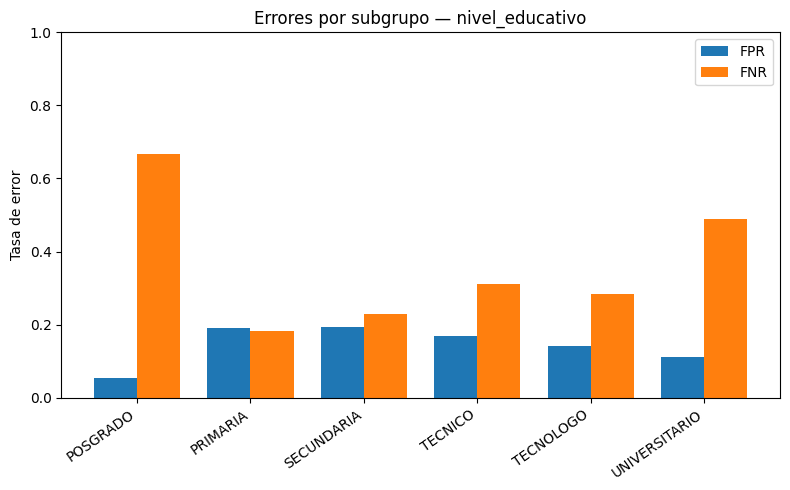

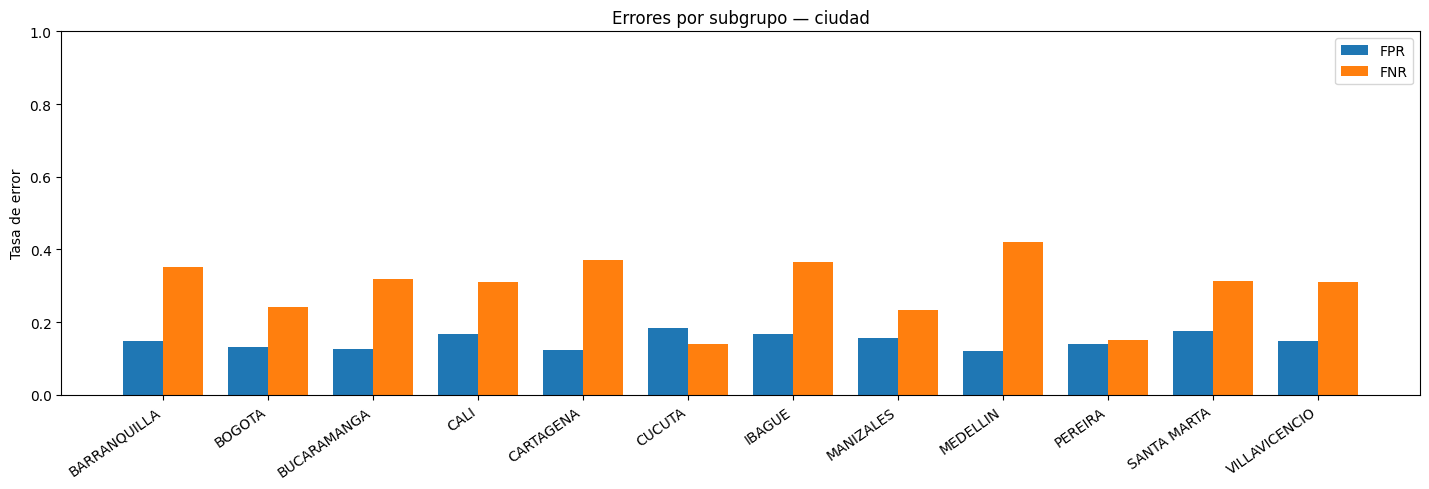

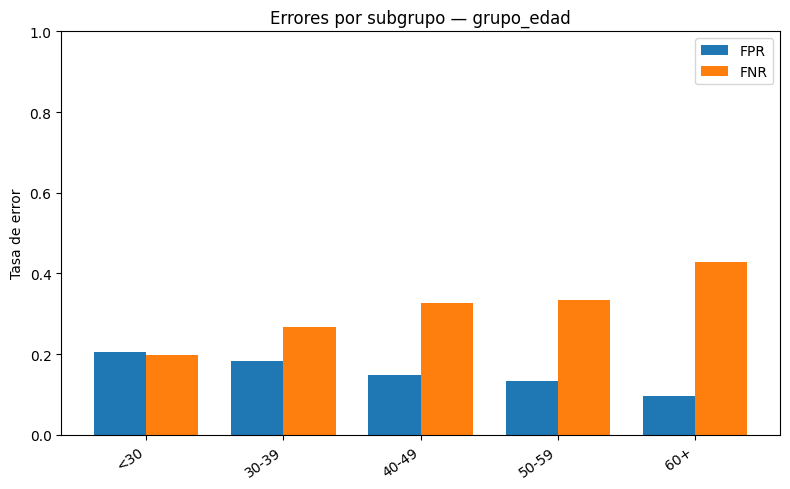

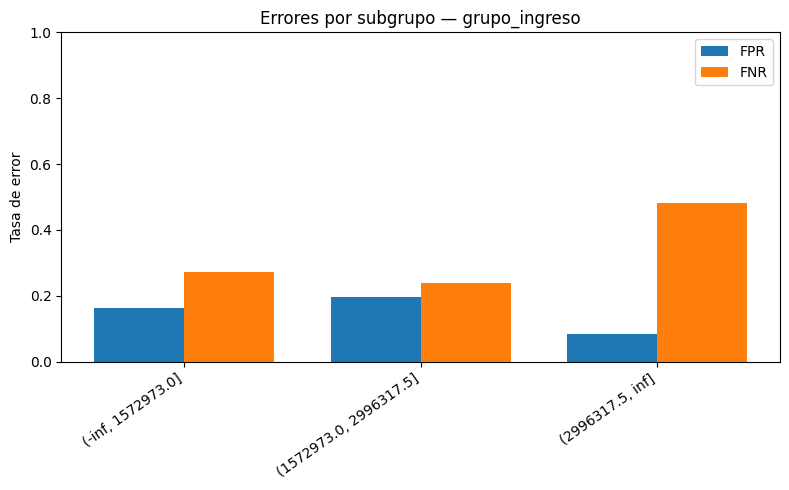

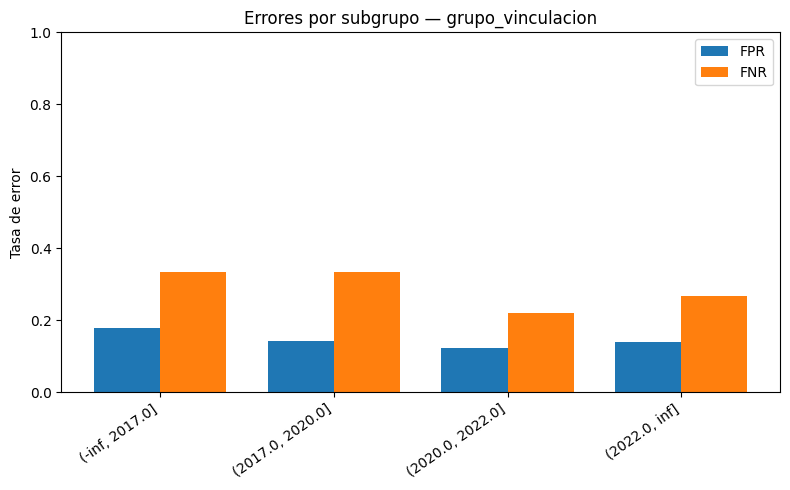

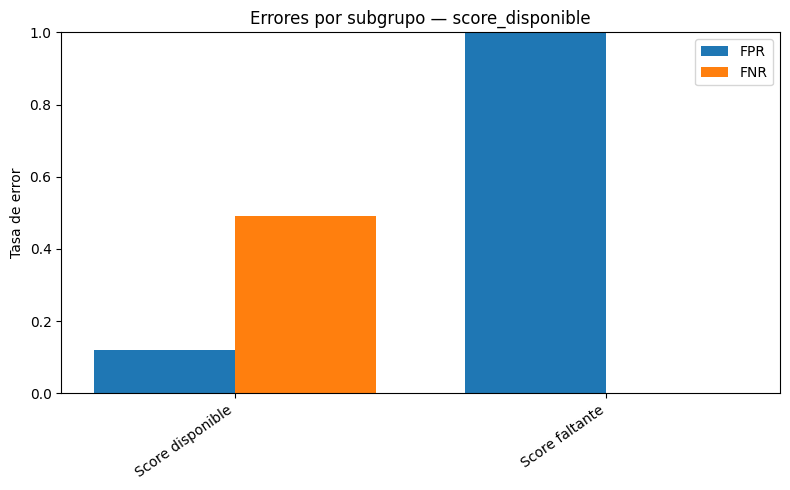

In [30]:
# Magnitud de las brechas entre grupos con tamaño suficiente.
MIN_N = 50
MIN_CLASS_COUNT = 10
fairness_metrics = ['tasa_alerta', 'precision', 'recall_tpr', 'f1', 'fpr', 'fnr', 'auc_roc']

disparity_rows = []
for group_col, table in subgroup_tables.items():
    eligible = table[
        (table['n'] >= MIN_N) &
        (table['positivos_reales'] >= MIN_CLASS_COUNT) &
        (table['negativos_reales'] >= MIN_CLASS_COUNT)
    ].copy()

    for metric in fairness_metrics:
        valid = eligible.dropna(subset=[metric])
        if len(valid) < 2:
            continue

        max_row = valid.loc[valid[metric].idxmax()]
        min_row = valid.loc[valid[metric].idxmin()]
        disparity_rows.append({
            'variable_grupo': group_col,
            'metrica': metric,
            'brecha_max_min': float(max_row[metric] - min_row[metric]),
            'grupo_max': max_row['grupo'],
            'valor_max': float(max_row[metric]),
            'grupo_min': min_row['grupo'],
            'valor_min': float(min_row[metric]),
            'n_grupos_elegibles': int(len(valid)),
        })

disparity_summary = pd.DataFrame(disparity_rows)

if not disparity_summary.empty:
    display(
        disparity_summary.sort_values('brecha_max_min', ascending=False)
        .round(4)
    )
else:
    print('No hubo suficientes grupos comparables con los criterios mínimos definidos.')

disparity_summary.to_csv(
    M4_OUTPUT_DIR / 'brechas_desempeno_subgrupos.csv',
    index=False,
    encoding='utf-8-sig',
)

# Visualización compacta de FPR y FNR por variable de segmentación.
for group_col, table in subgroup_tables.items():
    eligible_plot = table[table['n'] >= MIN_N].copy()
    if eligible_plot.empty:
        continue

    x = np.arange(len(eligible_plot))
    width = 0.38

    fig, ax = plt.subplots(figsize=(max(8, len(eligible_plot) * 1.2), 5))
    ax.bar(x - width / 2, eligible_plot['fpr'], width, label='FPR')
    ax.bar(x + width / 2, eligible_plot['fnr'], width, label='FNR')
    ax.set_xticks(x)
    ax.set_xticklabels(eligible_plot['grupo'], rotation=35, ha='right')
    ax.set_ylim(0, 1)
    ax.set_ylabel('Tasa de error')
    ax.set_title(f'Errores por subgrupo — {group_col}')
    ax.legend()
    plt.tight_layout()
    plt.savefig(
        M4_FIGURES_DIR / f'errores_subgrupo_{group_col}.png',
        dpi=300,
        bbox_inches='tight',
    )
    plt.show()

### 8.4.1 Matrices de confusión por subgrupo

Para dejar evidencia concreta de los errores dentro de cada segmento se generan matrices de confusión para `nivel_educativo`, `ciudad` y disponibilidad de `score_externo`. Se omiten grupos con menos de 50 observaciones para evitar figuras dominadas por tamaños muestrales muy pequeños.

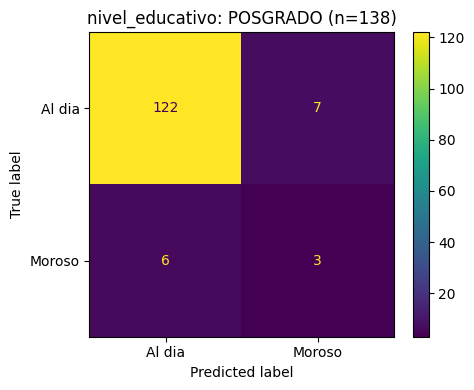

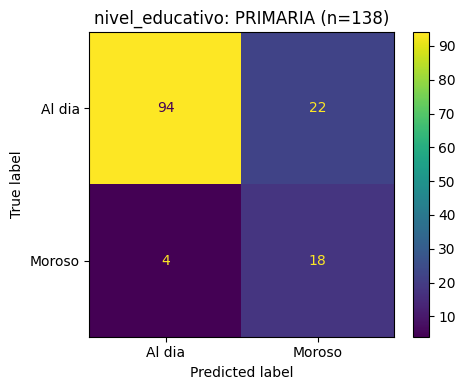

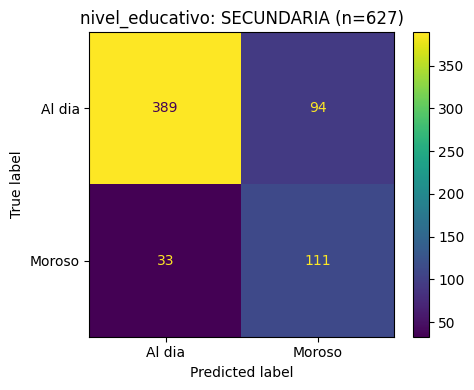

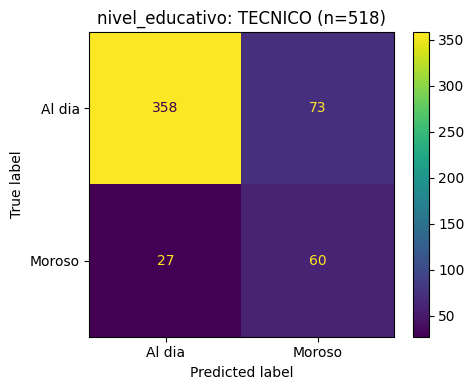

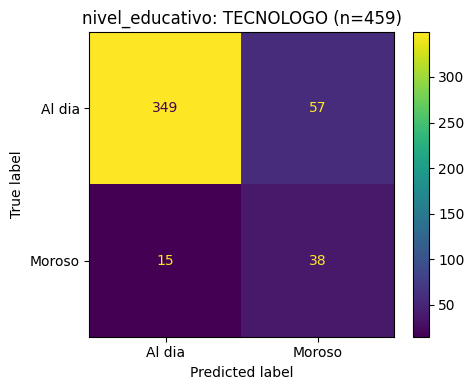

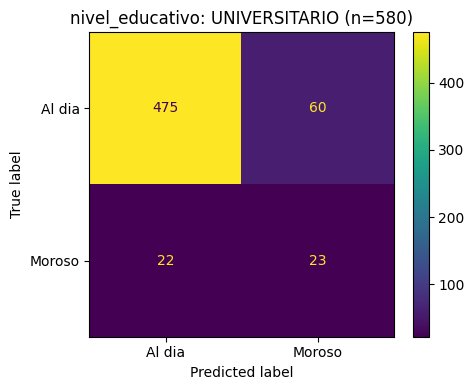

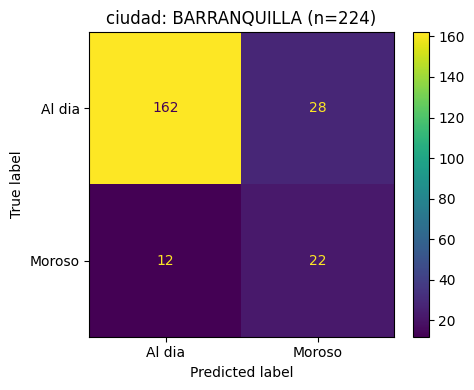

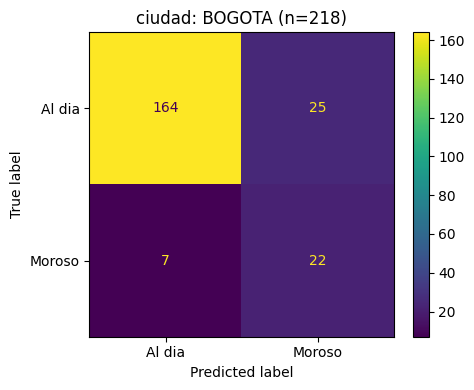

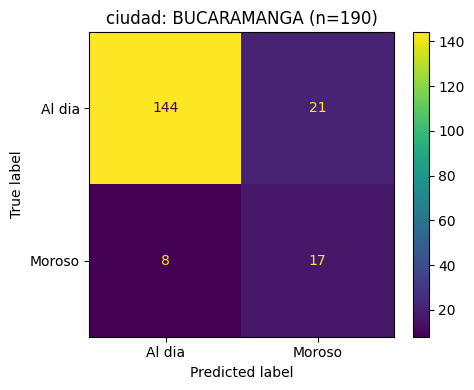

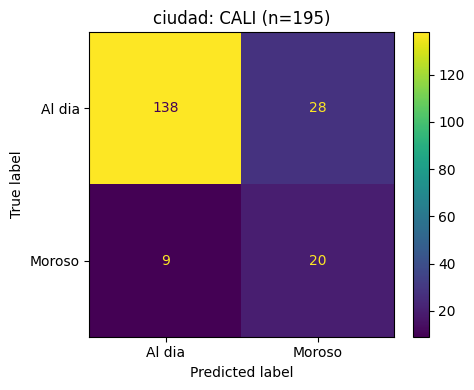

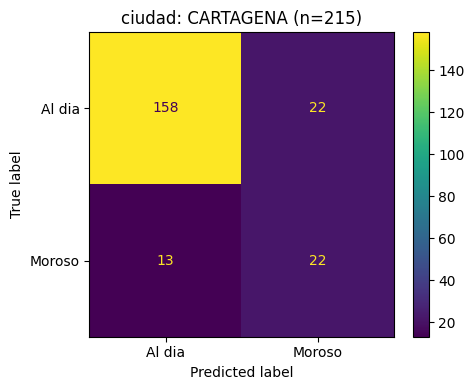

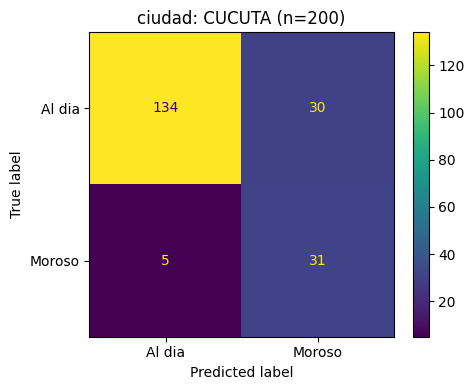

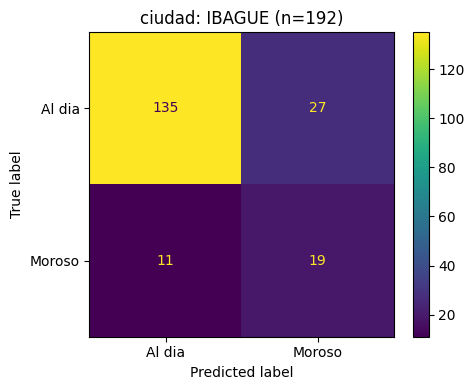

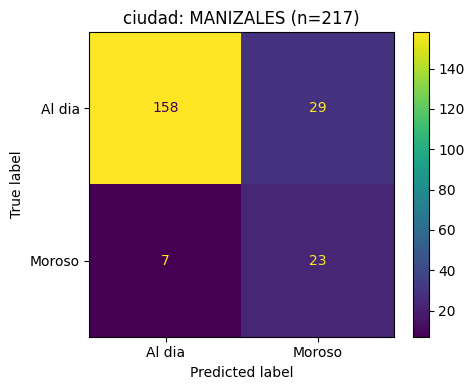

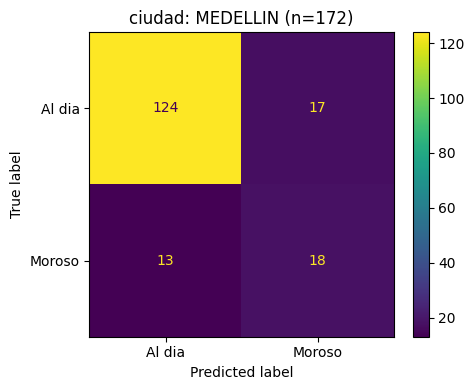

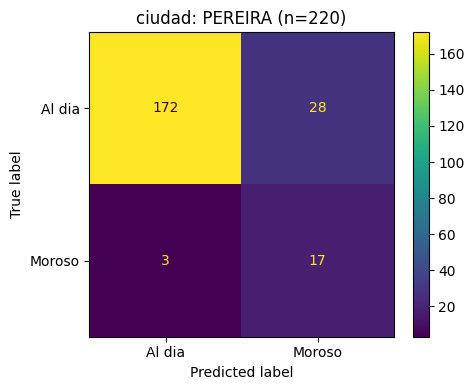

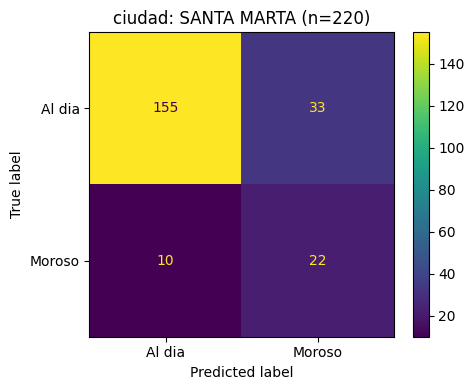

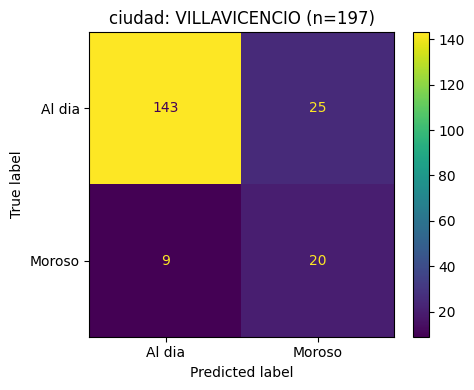

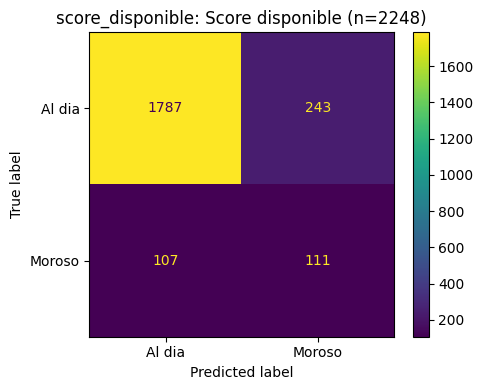

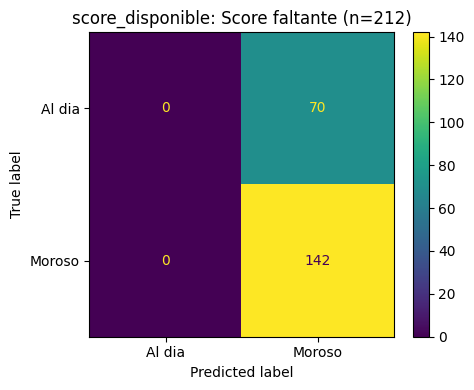

In [31]:
def safe_filename(value):
    value = str(value).strip().lower()
    value = re.sub(r'[^a-z0-9]+', '_', value)
    return value.strip('_') or 'grupo'

confusion_group_vars = ['nivel_educativo', 'ciudad', 'score_disponible']

for group_col in confusion_group_vars:
    table = subgroup_tables[group_col]
    eligible_groups = table.loc[table['n'] >= MIN_N, 'grupo'].tolist()

    for group_value in eligible_groups:
        subset = audit_test[audit_test[group_col].astype(str) == str(group_value)]
        if subset.empty:
            continue

        fig, ax = plt.subplots(figsize=(5, 4))
        ConfusionMatrixDisplay.from_predictions(
            subset[TARGET].astype(int),
            subset['pred_moroso'].astype(int),
            labels=[0, 1],
            display_labels=['Al dia', 'Moroso'],
            ax=ax,
        )
        ax.set_title(f'{group_col}: {group_value} (n={len(subset)})')
        plt.tight_layout()
        plt.savefig(
            M4_FIGURES_DIR /
            f'confusion_{safe_filename(group_col)}_{safe_filename(group_value)}.png',
            dpi=300,
            bbox_inches='tight',
        )
        plt.show()

## 8.5 Interpretabilidad global

Se aplican dos enfoques complementarios:

1. **Permutation importance:** mide cuánto cae el AUC-ROC al permutar cada predictor original. Es agnóstico al modelo y mantiene nombres de variables interpretables.
2. **SHAP:** descompone la contribución de las variables transformadas para una muestra del test. Se utiliza como evidencia adicional de qué características impulsan las predicciones.

La importancia o contribución de una variable **no implica causalidad**. En particular, una alta importancia de `ciudad` o `nivel_educativo` debe analizarse como posible señal de dependencia de variables sensibles al contexto, no como justificación automática para utilizarlas en decisiones adversas.

,feature,importance_mean,importance_std
3,score_externo,0.33606,0.01452
1,ingreso_mensual,0.02200,0.00369
0,edad,0.01027,0.00391
4,nivel_educativo,0.00943,0.00232
5,ciudad,-0.00039,0.00038
2,anio_vinculacion,-0.00074,0.00042


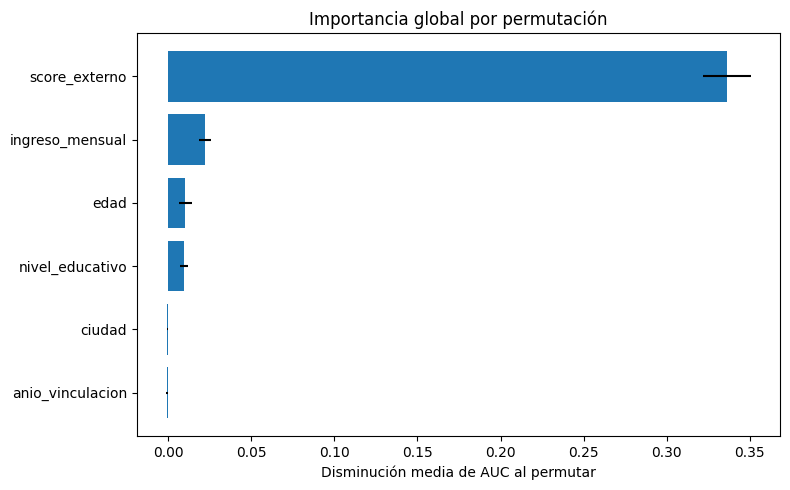

In [32]:
permutation = permutation_importance(
    best_pipeline,
    X_test,
    y_test,
    scoring='roc_auc',
    n_repeats=20,
    random_state=RANDOM_SEED,
    n_jobs=-1,
)

permutation_table = pd.DataFrame({
    'feature': FEATURES,
    'importance_mean': permutation.importances_mean,
    'importance_std': permutation.importances_std,
}).sort_values('importance_mean', ascending=False)

display(permutation_table.round(5))

permutation_table.to_csv(
    M4_OUTPUT_DIR / 'permutation_importance.csv',
    index=False,
    encoding='utf-8-sig',
)

plot_perm = permutation_table.sort_values('importance_mean')
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_perm['feature'], plot_perm['importance_mean'], xerr=plot_perm['importance_std'])
ax.set_xlabel('Disminución media de AUC al permutar')
ax.set_title('Importancia global por permutación')
plt.tight_layout()
plt.savefig(M4_FIGURES_DIR / 'permutation_importance.png', dpi=300, bbox_inches='tight')
plt.show()

### 8.5.1 Interpretabilidad con SHAP — global y local

Para cumplir el requisito de interpretabilidad se generan dos evidencias:

1. **SHAP summary plot:** resume las tres características transformadas con mayor contribución media absoluta y permite observar si empujan las predicciones hacia mayor o menor riesgo.
2. **SHAP waterfall:** explica un caso individual del conjunto de prueba, mostrando qué características aumentaron o redujeron la predicción respecto al valor base del modelo.

El cálculo utiliza `TreeExplainer` sobre el `HistGradientBoostingClassifier` ya entrenado. Se desactiva únicamente la comprobación numérica de aditividad (`check_additivity=False`) porque algunas versiones de SHAP pueden reportar diferencias de tolerancia con este estimador. Esto **no cambia el modelo, las predicciones ni los valores SHAP calculados**; evita que una verificación interna detenga la ejecución.

Las contribuciones SHAP describen asociaciones con la predicción del modelo y **no implican causalidad**.

In [ ]:
import shap

print("SHAP:", shap.__version__)

In [ ]:
# --- SHAP robusto para HistGradientBoosting + Pipeline ---
fitted_preprocessor = best_pipeline.named_steps["preprocessor"]
fitted_classifier = best_pipeline.named_steps["classifier"]

feature_names_transformed = np.asarray(
    fitted_preprocessor.get_feature_names_out(),
    dtype=object,
)

# Muestras reproducibles y de tamaño moderado para que el notebook sea ejecutable.
background_n = min(100, len(X_train))
explain_n = min(500, len(X_test))

X_background_raw = X_train.sample(
    n=background_n,
    random_state=RANDOM_SEED,
)
X_explain_raw = X_test.sample(
    n=explain_n,
    random_state=RANDOM_SEED,
)

X_background = np.asarray(
    fitted_preprocessor.transform(X_background_raw),
    dtype=float,
)
X_explain = np.asarray(
    fitted_preprocessor.transform(X_explain_raw),
    dtype=float,
)

# TreeExplainer en salida "raw" (log-odds) para compatibilidad estable.
shap_explainer = shap.TreeExplainer(
    fitted_classifier,
    data=X_background,
    feature_perturbation="interventional",
    model_output="raw",
)

shap_values_raw = shap_explainer.shap_values(
    X_explain,
    check_additivity=False,
)

# Compatibilidad entre versiones: algunas devuelven lista/3D.
if isinstance(shap_values_raw, list):
    shap_array = np.asarray(shap_values_raw[-1])
else:
    shap_array = np.asarray(shap_values_raw)

if shap_array.ndim == 3:
    shap_array = shap_array[:, :, -1]

if shap_array.shape[1] != len(feature_names_transformed):
    raise ValueError(
        "La cantidad de columnas SHAP no coincide con las variables transformadas: "
        f"{shap_array.shape[1]} vs {len(feature_names_transformed)}"
    )

# Importancia global por característica transformada.
mean_abs_shap = np.mean(np.abs(shap_array), axis=0)
shap_importance_transformed = (
    pd.DataFrame({
        "feature_transformada": feature_names_transformed,
        "mean_abs_shap": mean_abs_shap,
    })
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

# Mapeo a las variables originales para una lectura de negocio.
def original_feature_from_transformed(name):
    clean = str(name).split("__", 1)[-1]

    for feature in NUMERIC_FEATURES:
        if clean == feature:
            return feature

    for feature in CATEGORICAL_FEATURES:
        if clean == feature or clean.startswith(feature + "_"):
            return feature

    return clean

shap_importance_transformed["feature_original"] = (
    shap_importance_transformed["feature_transformada"]
    .map(original_feature_from_transformed)
)

# La importancia original se suma sobre dummies/categorías del mismo predictor.
shap_importance_original = (
    shap_importance_transformed
    .groupby("feature_original", as_index=False)["mean_abs_shap"]
    .sum()
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

display(shap_importance_original.round(6))
display(shap_importance_transformed.head(15).round(6))

shap_importance_original.to_csv(
    M4_OUTPUT_DIR / "shap_importance_original.csv",
    index=False,
    encoding="utf-8-sig",
)
shap_importance_transformed.to_csv(
    M4_OUTPUT_DIR / "shap_importance_transformada.csv",
    index=False,
    encoding="utf-8-sig",
)

# --- SHAP SUMMARY PLOT: top 3 características más influyentes ---
plt.figure(figsize=(9, 6))
shap.summary_plot(
    shap_array,
    X_explain,
    feature_names=feature_names_transformed,
    max_display=3,
    plot_type="dot",
    show=False,
)
summary_fig = plt.gcf()
summary_fig.suptitle(
    "SHAP summary plot — 3 características más influyentes",
    y=1.02,
)
summary_fig.tight_layout()
summary_fig.savefig(
    M4_FIGURES_DIR / "shap_summary_top3.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# --- Caso individual para waterfall ---
# Se prioriza un verdadero positivo; si no existe en la muestra, se usa el
# registro con mayor probabilidad estimada.
explain_indices = X_explain_raw.index
y_explain_true = y_test.loc[explain_indices].astype(int).to_numpy()
proba_explain = best_pipeline.predict_proba(X_explain_raw)[:, 1]
pred_explain = (proba_explain >= optimal_threshold).astype(int)

tp_positions = np.flatnonzero(
    (y_explain_true == 1) & (pred_explain == 1)
)

if len(tp_positions) > 0:
    local_pos = int(tp_positions[0])
    local_case_type = "Verdadero positivo"
else:
    local_pos = int(np.argmax(proba_explain))
    local_case_type = "Caso con mayor probabilidad de mora en la muestra"

expected_value = float(
    np.asarray(shap_explainer.expected_value).reshape(-1)[0]
)

local_explanation = shap.Explanation(
    values=shap_array[local_pos],
    base_values=expected_value,
    data=X_explain[local_pos],
    feature_names=feature_names_transformed,
)

shap.plots.waterfall(
    local_explanation,
    max_display=10,
    show=False,
)
waterfall_fig = plt.gcf()
waterfall_fig.suptitle(
    f"SHAP waterfall — caso individual ({local_case_type})",
    y=1.02,
)
waterfall_fig.tight_layout()
waterfall_fig.savefig(
    M4_FIGURES_DIR / "shap_waterfall_caso_individual.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

local_case_index = explain_indices[local_pos]
local_case_raw = X_test.loc[[local_case_index]].copy()
local_case_table = local_case_raw.copy()
local_case_table["y_real"] = int(y_test.loc[local_case_index])
local_case_table["probabilidad_mora"] = float(proba_explain[local_pos])
local_case_table["prediccion_moroso"] = int(pred_explain[local_pos])
local_case_table["threshold"] = float(optimal_threshold)

display(local_case_table)

local_case_table.to_csv(
    M4_OUTPUT_DIR / "shap_caso_individual.csv",
    index=True,
    encoding="utf-8-sig",
)

# Interpretación automática, en lenguaje de negocio, de las 3 variables
# originales más influyentes.
top3_original = shap_importance_original.head(3).copy()

BUSINESS_INTERPRETATION = {
    "score_externo": (
        "El score externo concentra señal de riesgo crediticio proveniente de una "
        "fuente externa. Su alta influencia exige controlar cobertura, calidad y "
        "finalidad de uso, especialmente cuando el dato está ausente."
    ),
    "ingreso_mensual": (
        "El ingreso mensual representa capacidad económica declarada. Debe "
        "interpretarse con cautela porque valores bajos o cero pueden responder "
        "a situaciones reales o a problemas de calidad de datos."
    ),
    "edad": (
        "La edad aporta información de perfil. Si su contribución es relevante, "
        "debe monitorearse el desempeño por grupos etarios para evitar impactos "
        "desiguales no justificados por el objetivo del modelo."
    ),
    "anio_vinculacion": (
        "El año de vinculación aproxima la antigüedad de la relación con el cliente. "
        "Su uso debe mantenerse limitado a información disponible antes de la decisión."
    ),
    "nivel_educativo": (
        "El nivel educativo es una variable de perfil que puede actuar como proxy "
        "de condiciones socioeconómicas; por ello requiere seguimiento de equidad."
    ),
    "ciudad": (
        "La ciudad puede capturar diferencias regionales y también actuar como proxy "
        "de condiciones socioeconómicas; requiere monitoreo por subgrupos."
    ),
}

print("\nTop 3 variables originales por importancia SHAP:")
for rank, row in top3_original.reset_index(drop=True).iterrows():
    feature = row["feature_original"]
    importance = row["mean_abs_shap"]
    print(f"{rank + 1}. {feature}: mean(|SHAP|) = {importance:.6f}")
    print("   Lectura de negocio:", BUSINESS_INTERPRETATION.get(
        feature,
        "Variable con contribución relevante; debe interpretarse en el contexto de negocio."
    ))

print("\nCaso local explicado:")
print("Tipo:", local_case_type)
print("Índice:", local_case_index)
print(f"Probabilidad de mora: {proba_explain[local_pos]:.4f}")
print(f"Threshold operativo: {optimal_threshold:.2f}")
print(f"Clase real: {int(y_test.loc[local_case_index])}")
print(f"Predicción: {int(pred_explain[local_pos])}")
print("\nSHAP completado correctamente: True")

## 8.6 Sesgos y equidad — métricas formales

Además de comparar precision, recall, FPR, FNR y AUC por subgrupo, se formalizan métricas de equidad:

- **Equal Opportunity Difference (EOD):** diferencia entre el mayor y el menor `recall/TPR` de los grupos elegibles. Un valor de 0 indica igualdad de oportunidad perfecta respecto a la detección de morosos.
- **FPR Difference:** diferencia entre la mayor y la menor tasa de falsos positivos. Permite identificar si ciertos grupos de clientes al día reciben alertas con mayor frecuencia.
- **Demographic Parity Difference (DPD):** diferencia entre tasas de alerta. Se reporta únicamente como señal descriptiva, porque la prevalencia real de mora puede variar entre grupos.

Estas métricas no prueban discriminación causal; identifican brechas que deben investigarse y monitorearse.

In [ ]:
fairness_rows = []

for group_col, table in subgroup_tables.items():
    eligible = table[
        (table["n"] >= MIN_N) &
        (table["positivos_reales"] >= MIN_CLASS_COUNT) &
        (table["negativos_reales"] >= MIN_CLASS_COUNT)
    ].copy()

    if len(eligible) < 2:
        continue

    fairness_rows.append({
        "variable_grupo": group_col,
        "n_grupos_elegibles": int(len(eligible)),
        "equal_opportunity_difference": float(
            eligible["recall_tpr"].max() - eligible["recall_tpr"].min()
        ),
        "fpr_difference": float(
            eligible["fpr"].max() - eligible["fpr"].min()
        ),
        "demographic_parity_difference": float(
            eligible["tasa_alerta"].max() - eligible["tasa_alerta"].min()
        ),
        "recall_max_grupo": str(
            eligible.loc[eligible["recall_tpr"].idxmax(), "grupo"]
        ),
        "recall_min_grupo": str(
            eligible.loc[eligible["recall_tpr"].idxmin(), "grupo"]
        ),
    })

fairness_summary = (
    pd.DataFrame(fairness_rows)
    .sort_values("equal_opportunity_difference", ascending=False)
    .reset_index(drop=True)
)

display(fairness_summary.round(4))

fairness_summary.to_csv(
    M4_OUTPUT_DIR / "metricas_equidad_subgrupos.csv",
    index=False,
    encoding="utf-8-sig",
)

if not fairness_summary.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(fairness_summary))
    width = 0.26

    ax.bar(
        x - width,
        fairness_summary["equal_opportunity_difference"],
        width,
        label="Equal Opportunity Difference",
    )
    ax.bar(
        x,
        fairness_summary["fpr_difference"],
        width,
        label="FPR Difference",
    )
    ax.bar(
        x + width,
        fairness_summary["demographic_parity_difference"],
        width,
        label="Demographic Parity Difference",
    )
    ax.set_xticks(x)
    ax.set_xticklabels(
        fairness_summary["variable_grupo"],
        rotation=30,
        ha="right",
    )
    ax.set_ylabel("Brecha absoluta")
    ax.set_title("Métricas de equidad por segmentación")
    ax.legend()
    plt.tight_layout()
    plt.savefig(
        M4_FIGURES_DIR / "metricas_equidad_subgrupos.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    worst_eq = fairness_summary.iloc[0]
    print(
        "Mayor Equal Opportunity Difference:",
        f'{worst_eq["equal_opportunity_difference"]:.4f}',
        "en",
        worst_eq["variable_grupo"],
    )
    print(
        "Recall mayor:",
        worst_eq["recall_max_grupo"],
        "| Recall menor:",
        worst_eq["recall_min_grupo"],
    )

## 8.7 Límites de uso: cuándo SOLARIS **no** debería utilizarse

La evidencia técnica permite considerar SOLARIS como herramienta de apoyo, pero **no** como decisión automática. El modelo no debería utilizarse:

- Para aprobar, negar o reducir crédito de forma autónoma, sin revisión humana.
- Como regla automática adversa cuando `score_externo` esté ausente; esos casos requieren una ruta de revisión separada.
- Fuera de la población y del contexto de datos evaluados sin una validación previa.
- Si cambian de forma material la cobertura, definición o calidad de los predictores.
- Como evidencia de estabilidad temporal definitiva: aún no existe una validación `out-of-time` con `fecha_corte` y `fecha_evento`.

Estos límites convierten las métricas en condiciones concretas de gobernanza y evitan interpretar un buen AUC como autorización para automatizar decisiones de crédito.

## 8.8 Registro de riesgos e implicaciones éticas

La tabla se limita a **cuatro riesgos específicos de SOLARIS**, tal como exige la actividad. La probabilidad se expresa cualitativamente a partir de la evidencia observada y el impacto se cuantifica cuando el dataset lo permite.

In [ ]:
# Métricas auxiliares para cuantificar riesgos.
n_test = int(len(y_test))
n_negative_test = int((y_test == 0).sum())
fp_rate_over_negatives = float(fp / n_negative_test) if n_negative_test else np.nan

score_missing_metrics = subgroup_tables["score_disponible"].copy()
score_missing_row = score_missing_metrics[
    score_missing_metrics["grupo"] == "Score faltante"
]
score_missing_n = (
    int(score_missing_row.iloc[0]["n"])
    if not score_missing_row.empty else 0
)
score_missing_alert = (
    float(score_missing_row.iloc[0]["tasa_alerta"])
    if not score_missing_row.empty else np.nan
)
score_missing_fpr = (
    float(score_missing_row.iloc[0]["fpr"])
    if not score_missing_row.empty else np.nan
)

if not fairness_summary.empty:
    top_fairness = fairness_summary.iloc[0]
    fairness_group_name = str(top_fairness["variable_grupo"])
    fairness_eod = float(top_fairness["equal_opportunity_difference"])
else:
    fairness_group_name = "No disponible"
    fairness_eod = np.nan

risk_table = pd.DataFrame([
    {
        "riesgo": "Ausencia de score_externo usada como señal adversa",
        "severidad": "Alta",
        "probabilidad": "Media-Alta",
        "impacto_negocio": (
            f"{score_missing_n} casos de test sin score; "
            f"tasa de alerta={score_missing_alert:.1%} y FPR={score_missing_fpr:.1%}. "
            "Puede generar revisiones o restricciones injustificadas."
        ),
        "mitigacion_realizable": (
            "Ruta obligatoria de revisión humana; auditar el mecanismo de ausencia "
            "y prohibir decisiones adversas basadas únicamente en el faltante."
        ),
    },
    {
        "riesgo": "Brechas de desempeño entre subgrupos",
        "severidad": "Alta",
        "probabilidad": "Media",
        "impacto_negocio": (
            f"Mayor Equal Opportunity Difference={fairness_eod:.4f} "
            f"en {fairness_group_name}. Puede producir diferente capacidad "
            "de detección entre segmentos."
        ),
        "mitigacion_realizable": (
            "Monitorear mensualmente recall/TPR, FPR, FNR y EOD por subgrupo; "
            "investigar y ajustar si las brechas aumentan."
        ),
    },
    {
        "riesgo": "Falsos positivos en decisiones de crédito",
        "severidad": "Media-Alta",
        "probabilidad": "Alta",
        "impacto_negocio": (
            f"{fp} falsos positivos en {n_test} casos de test; "
            f"{fp_rate_over_negatives:.1%} de los clientes Al día del test "
            "reciben una alerta falsa."
        ),
        "mitigacion_realizable": (
            "Mantener el threshold gobernado fuera de test, revisión humana y "
            "política de excepción/apelación antes de cualquier decisión adversa."
        ),
    },
    {
        "riesgo": "Generalización temporal no demostrada",
        "severidad": "Alta",
        "probabilidad": "Media (no medida OOT)",
        "impacto_negocio": (
            "0 validaciones out-of-time disponibles. El AUC test actual "
            f"({auc_test:.4f}) proviene de un split IID y no cuantifica la caída futura."
        ),
        "mitigacion_realizable": (
            "Construir snapshots con fecha_corte/fecha_evento y exigir validación "
            "out-of-time antes de producción; monitorear drift y calibración."
        ),
    },
])

display(risk_table)

risk_table.to_csv(
    M4_OUTPUT_DIR / "registro_riesgos_modulo4.csv",
    index=False,
    encoding="utf-8-sig",
)

### Implicación ética y salvaguardas

SOLARIS influye potencialmente en decisiones humanas sobre **aprobar, mantener, reducir o negar cupos y priorizar cobranza**. Por ello, un error del modelo puede afectar tanto la exposición financiera de FrescaMar como el acceso al crédito de clientes cumplidos. Las salvaguardas propuestas son: revisión humana obligatoria, explicación del score, trazabilidad de la versión del modelo, política de excepciones, monitoreo de equidad y prohibición de usar la ausencia de `score_externo` como motivo automático para una decisión adversa.

## 8.9 Recomendación final de despliegue

### **Recomendación: desplegar únicamente como piloto controlado y con condiciones**

La evidencia permite utilizar SOLARIS como herramienta de **priorización y apoyo a la decisión**, pero no como sistema autónomo de crédito. El despliegue debería condicionarse a:

1. **Revisión humana obligatoria** antes de cualquier reducción o negación de cupo.
2. **Ruta separada para `score_externo` faltante**, sin sanción automática por ausencia.
3. **Monitoreo periódico de equidad**, especialmente Equal Opportunity Difference, FPR y FNR por edad, ingreso, educación, ciudad y disponibilidad del score.
4. **Validación out-of-time** antes de pasar de piloto a producción.
5. **Monitoreo de calidad y drift** de los predictores y de la calibración.
6. Mantener el **threshold y los hiperparámetros gobernados fuera del conjunto de test**.

Con estas condiciones, el modelo puede aportar valor operativo manteniendo límites claros de uso y responsabilidad humana.

## 8.10 Resumen exportable y checklist de la entrega

Esta última celda genera un JSON con las métricas necesarias para el informe y verifica que el notebook produzca las evidencias exigidas: métricas de test, validación cruzada, baseline, matriz de confusión, SHAP global/local, análisis de sesgos, métrica formal de equidad, riesgos y recomendación final.

In [ ]:
def get_cv_mean(model_name, metric):
    row = cv_multimetric_summary[
        (cv_multimetric_summary["modelo"] == model_name) &
        (cv_multimetric_summary["metrica"] == metric)
    ]
    return float(row.iloc[0]["media"]) if not row.empty else None

m4_summary = {
    "modelo_auditado": "HistGradientBoostingClassifier optimizado con Optuna",
    "threshold_congelado": float(optimal_threshold),
    "validacion_cruzada": {
        "hgb_auc_media": get_cv_mean("HGB + Optuna", "auc_roc"),
        "hgb_precision_media": get_cv_mean("HGB + Optuna", "precision"),
        "hgb_recall_media": get_cv_mean("HGB + Optuna", "recall"),
        "hgb_f1_media": get_cv_mean("HGB + Optuna", "f1"),
        "baseline_auc_media": get_cv_mean("Regresion Logistica", "auc_roc"),
    },
    "test": {
        "auc_roc": float(auc_test),
        "precision": float(precision_test),
        "recall": float(recall_test),
        "f1": float(f1_test),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    },
    "shap": {
        "summary_plot": str(M4_FIGURES_DIR / "shap_summary_top3.png"),
        "waterfall": str(M4_FIGURES_DIR / "shap_waterfall_caso_individual.png"),
        "top3_original": shap_importance_original.head(3).to_dict(orient="records"),
        "caso_individual_indice": str(local_case_index),
        "caso_individual_probabilidad": float(proba_explain[local_pos]),
    },
    "equidad": fairness_summary.to_dict(orient="records"),
    "robustez_score_externo": robustness_summary.to_dict(orient="records"),
    "brechas_subgrupos": disparity_summary.to_dict(orient="records"),
    "riesgos": risk_table.to_dict(orient="records"),
    "recomendacion_despliegue": (
        "Desplegar únicamente como piloto controlado y con condiciones; "
        "no usar como sistema autónomo de decisión crediticia."
    ),
    "limitaciones": [
        "No hay variables de sexo, raza o etnia en el dataset disponible.",
        "Las brechas por subgrupo son descriptivas y no demuestran discriminación causal.",
        "No existe todavía validación out-of-time con fecha_corte/fecha_evento.",
    ],
}

with open(
    M4_OUTPUT_DIR / "resumen_evaluacion_critica_modulo4.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(m4_summary, file, ensure_ascii=False, indent=2, default=str)

required_figures = [
    M4_FIGURES_DIR / "shap_summary_top3.png",
    M4_FIGURES_DIR / "shap_waterfall_caso_individual.png",
    M4_FIGURES_DIR / "metricas_equidad_subgrupos.png",
]

print("\nCHECKLIST — ENTREGA MÓDULO 4")
print("✓ Métricas reportadas en TEST")
print("✓ Validación cruzada estratificada")
print("✓ Comparación contra baseline simple")
print("✓ Matriz de confusión + lectura de negocio")
print("✓ Casos en los que el modelo NO debe usarse")
print("✓ SHAP summary plot con top 3")
print("✓ SHAP waterfall de caso individual")
print("✓ Interpretación de negocio de las variables SHAP")
print("✓ Análisis por subgrupos")
print("✓ Equal Opportunity Difference y otras métricas de equidad")
print("✓ Tabla de máximo 4 riesgos con severidad, probabilidad, impacto y mitigación")
print("✓ Recomendación final: piloto controlado con condiciones")

print("\nFiguras obligatorias:")
for path in required_figures:
    print("✓" if path.exists() else "✗", path)

missing_required = [str(path) for path in required_figures if not path.exists()]
if missing_required:
    raise FileNotFoundError(
        "Faltan figuras obligatorias: " + ", ".join(missing_required)
    )

print("\nNotebook listo para sustentar el Informe de Evaluación Crítica.")